In [1]:
import io
import os
import math
import contextlib

import numpy as np
import torch
import matplotlib.pyplot as plt

# make sure the repo root is on the path
import sys
sys.path.insert(0, '.')

# import the two analysis scripts as modules
from analysis import elm as NT
from analysis import mechanistic as MA
from analysis.model import load_from_checkpoint

torch.set_default_dtype(torch.float64)

In [2]:
BLOCK_SIZE    = 2
NUM_TRAJ      = 10000
NOISE_SCALE   = 0.1
CHECKPOINT_DIR = './checkpoints/kepler_cv_blocksize_elm'
N_WINDOWS     = 200       # for Jacobian-based analyses (expensive)
N_WINDOWS_BEH = 4000      # for behavioural analyses (cheap forward passes)
SEED          = 0

checkpoint_path = (
    f'{CHECKPOINT_DIR}/model_block_size_{BLOCK_SIZE}'
    f'_num_trajectories_{NUM_TRAJ}_noise_scale_{NOISE_SCALE}.pt'
)

#checkpoint_path = './checkpoints/kepler_cv_blocksize_elm/model_block_size_2_num_trajectories_10000_noise_scale_0.0_rollout_20.pt'

assert os.path.exists(checkpoint_path), f"Checkpoint not found: {checkpoint_path}"
print(f"Checkpoint: {checkpoint_path}")

Checkpoint: ./checkpoints/kepler_cv_blocksize_elm/model_block_size_2_num_trajectories_10000_noise_scale_0.1.pt


In [3]:
# ── train/test split toggle for the mechanistic analysis ────────────────────
# Training splits the dataset 50/50 BY TRAJECTORY: train = first NUM_TRAJ, test = rest.
from analysis.data import load_trajectories

SPLIT  = 'test'                               # 'train' or 'test'
OFFSET = 0 if SPLIT == 'train' else NUM_TRAJ   # NUM_TRAJ (=10000) is the train/test boundary
print(f"Analysis split: {SPLIT}  (trajectory offset = {OFFSET})")

# helper for the cells that call load_trajectories directly (rollout plots, panel 2)
def load_split_trajectories(n, data_dir='data_cv', offset=None):
    offset = OFFSET if offset is None else offset
    with contextlib.redirect_stdout(io.StringIO()):
        trajs = np.asarray(load_trajectories(data_dir, num_trajectories_needed=offset + n))
    return trajs[offset:offset + n]

Analysis split: test  (trajectory offset = 10000)


In [4]:
# Cell 2 — load model and sample windows
with contextlib.redirect_stdout(io.StringIO()):
    model, ckpt = load_from_checkpoint(checkpoint_path, device='cpu')
model.eval()
print(f"Model loaded — step {ckpt.get('step', '?')}")
print(f"Config: {model.config}")

# sample real-orbit windows
windows = NT.sample_orbit_windows(BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
print(f"\nSampled {windows.shape[0]} windows of shape {windows.shape[1:]}")

Model loaded — step 20000
Config: GPTConfigCV(block_size=2, n_layer=2, n_head=1, n_embd=32, dropout=0.0, bias=False, input_dim=2, attention_alpha=0.0)

Sampled 200 windows of shape (2, 2)


In [5]:
# Cell 3 — collect Jacobian blocks (slow — ~1-2 min for N_WINDOWS=200)
all_blocks, coeffs, recon_err_max = NT.collect(model, BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
T = coeffs.shape[1]
D = all_blocks.shape[-1]

print(f"Jacobian blocks collected")
print(f"  all_blocks shape: {all_blocks.shape}  (n_windows, T, D, D)")
print(f"  max recon_err:    {recon_err_max:.2e}  (should be < 1e-10)")
print(f"\nIsotropic coefficients c_s = trace(J_s)/D:")
c_mean, c_std = coeffs.mean(0), coeffs.std(0)
for s in range(T):
    tag = '  <- recent (Verlet target  2)' if s == T-1 else \
          '  <- prev   (Verlet target -1)' if s == T-2 else ''
    print(f"  pos {s}: {c_mean[s]:+.3f} +/- {c_std[s]:.3f}{tag}")

Jacobian blocks collected
  all_blocks shape: (200, 2, 2, 2)  (n_windows, T, D, D)
  max recon_err:    8.07e-16  (should be < 1e-10)

Isotropic coefficients c_s = trace(J_s)/D:
  pos 0: +0.360 +/- 0.113  <- prev   (Verlet target -1)
  pos 1: +0.617 +/- 0.089  <- recent (Verlet target  2)


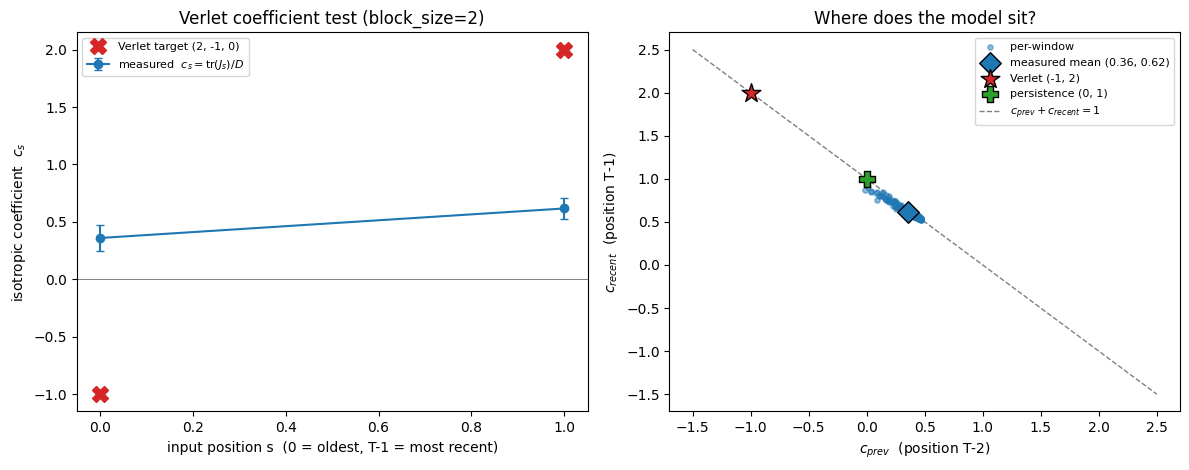

In [6]:
# Cell 4 — Verlet coefficient plot (inline)
positions = np.arange(T)
c_mean, c_std = coeffs.mean(0), coeffs.std(0)

target = np.zeros(T)
target[T-1] = 2.0
target[T-2] = -1.0

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

ax = axes[0]
ax.axhline(0, color='gray', lw=0.7)
ax.errorbar(positions, c_mean, yerr=c_std, fmt='-o', color='tab:blue',
            capsize=3, label=r'measured  $c_s=\mathrm{tr}(J_s)/D$')
ax.plot(positions, target, 'X', color='tab:red', ms=12,
        label='Verlet target (2, -1, 0)')
ax.set_xlabel('input position s  (0 = oldest, T-1 = most recent)')
ax.set_ylabel('isotropic coefficient  $c_s$')
ax.set_title(f'Verlet coefficient test (block_size={BLOCK_SIZE})')
ax.legend(fontsize=8)

ax = axes[1]
c_prev, c_recent = coeffs[:, T-2], coeffs[:, T-1]
ax.scatter(c_prev, c_recent, s=14, alpha=0.5, color='tab:blue',
           label='per-window', zorder=2)
ax.scatter([c_prev.mean()], [c_recent.mean()], s=120, marker='D',
           color='tab:blue', edgecolor='k',
           label=f'measured mean ({c_prev.mean():.2f}, {c_recent.mean():.2f})',
           zorder=4)
ax.scatter([-1], [2], s=200, marker='*', color='tab:red', edgecolor='k',
           label='Verlet (-1, 2)', zorder=5)
ax.scatter([0], [1], s=120, marker='P', color='tab:green', edgecolor='k',
           label='persistence (0, 1)', zorder=4)
lo = min(-1.5, float(c_prev.min()))
hi = max(2.5, float(c_recent.max()))
xs = np.linspace(lo, hi, 50)
ax.plot(xs, 1 - xs, ls='--', color='gray', lw=1,
        label=r'$c_{prev}+c_{recent}=1$', zorder=1)
ax.set_xlabel(r'$c_{prev}$  (position T-2)')
ax.set_ylabel(r'$c_{recent}$  (position T-1)')
ax.set_title('Where does the model sit?')
ax.legend(fontsize=8, loc='best')

fig.tight_layout()
plt.show()

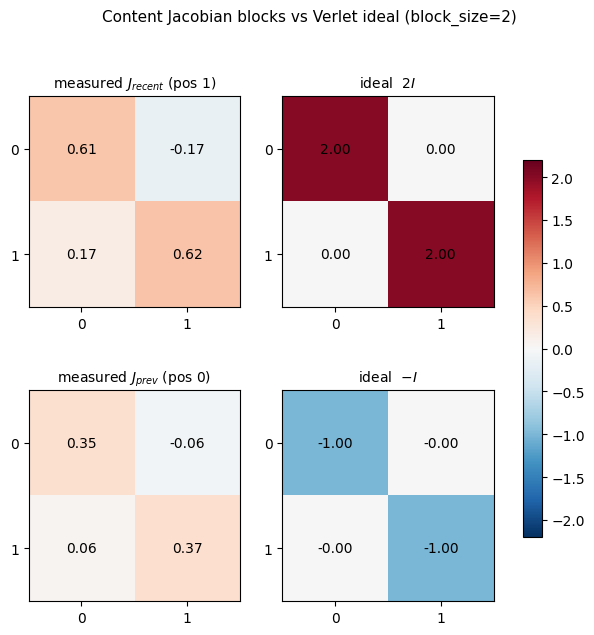

In [7]:
# Cell 5 — Jacobian block heatmaps vs Verlet ideal (inline)
meanJ = all_blocks.mean(0)   # (T, D, D) — mean across windows
J_recent = meanJ[T-1]
J_prev   = meanJ[T-2]
ideal_recent = 2  * np.eye(D)
ideal_prev   = -1 * np.eye(D)

panels = [
    (J_recent, f'measured $J_{{recent}}$ (pos {T-1})'),
    (ideal_recent, 'ideal  $2I$'),
    (J_prev,   f'measured $J_{{prev}}$ (pos {T-2})'),
    (ideal_prev,   'ideal  $-I$'),
]

fig, axes = plt.subplots(2, 2, figsize=(7.5, 7))
vmax = 2.2
for ax, (mat, title) in zip(axes.ravel(), panels):
    im = ax.imshow(mat, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax.set_title(title, fontsize=10)
    ax.set_xticks(range(D)); ax.set_yticks(range(D))
    for i in range(D):
        for j in range(D):
            ax.text(j, i, f'{mat[i,j]:.2f}', ha='center', va='center',
                    color='k', fontsize=10)

fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.7)
fig.suptitle(f'Content Jacobian blocks vs Verlet ideal (block_size={BLOCK_SIZE})', fontsize=11)
plt.show()

prev (t-1):
  diagonal diff:     mean=-0.0129, std=0.0279
  sym off-diagonal:  mean=+0.0019, std=0.0053
  rotation score:    mean=0.8878, std=0.1243
  rotation angle:    mean=+13.58, std=15.88 deg

recent (t):
  diagonal diff:     mean=-0.0099, std=0.0174
  sym off-diagonal:  mean=+0.0016, std=0.0111
  rotation score:    mean=0.9534, std=0.0529
  rotation angle:    mean=+13.53, std=8.46 deg



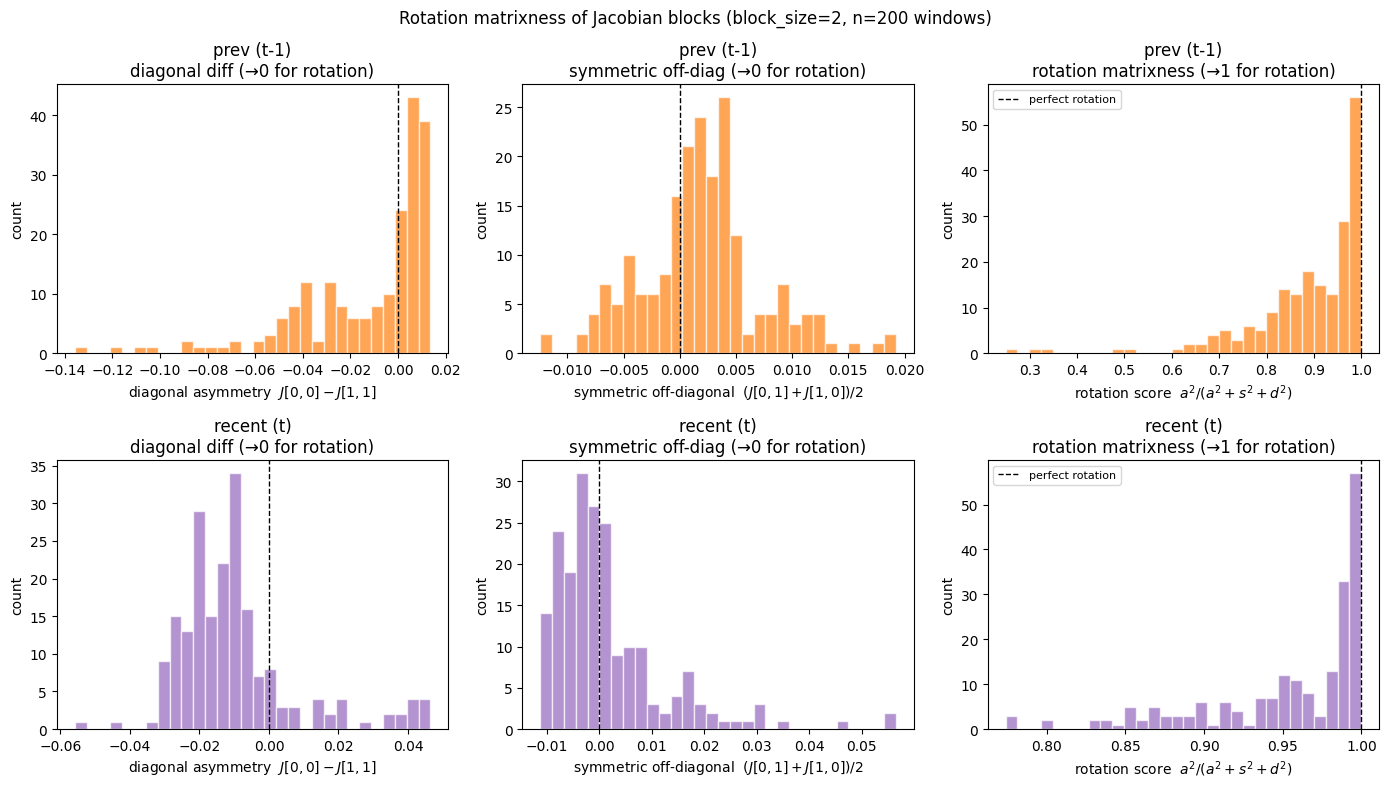

In [8]:
# Cell 6d — rotation matrixness across many windows
n_check = len(all_blocks)  # use all windows

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

labels = ['prev (t-1)', 'recent (t)']
colors = ['tab:orange', 'tab:purple']

for row, (s, label, color) in enumerate(zip([T-2, T-1], labels, colors)):
    J = all_blocks[:, s]   # (n_windows, 2, 2)

    diag_mean      = (J[:, 0, 0] + J[:, 1, 1]) / 2      # scale
    diag_diff      = J[:, 0, 0] - J[:, 1, 1]             # diagonal asymmetry
    sym_offdiag    = (J[:, 0, 1] + J[:, 1, 0]) / 2       # shear
    anti_offdiag   = (J[:, 1, 0] - J[:, 0, 1]) / 2       # rotation generator
    angle          = np.degrees(np.arctan2(anti_offdiag, diag_mean))

    # rotation matrixness score: how much of the block is captured by scaled rotation
    # a perfect scaled rotation has diag_diff=0 and sym_offdiag=0
    rot_score = anti_offdiag**2 / (anti_offdiag**2 + sym_offdiag**2 + diag_diff**2 + 1e-10)

    axes[row, 0].hist(diag_diff, bins=30, color=color, alpha=0.7, edgecolor='white')
    axes[row, 0].axvline(0, color='k', lw=1, linestyle='--')
    axes[row, 0].set_xlabel('diagonal asymmetry  $J[0,0] - J[1,1]$')
    axes[row, 0].set_ylabel('count')
    axes[row, 0].set_title(f'{label}\ndiagonal diff (→0 for rotation)')

    axes[row, 1].hist(sym_offdiag, bins=30, color=color, alpha=0.7, edgecolor='white')
    axes[row, 1].axvline(0, color='k', lw=1, linestyle='--')
    axes[row, 1].set_xlabel('symmetric off-diagonal  $(J[0,1]+J[1,0])/2$')
    axes[row, 1].set_ylabel('count')
    axes[row, 1].set_title(f'{label}\nsymmetric off-diag (→0 for rotation)')

    axes[row, 2].hist(rot_score, bins=30, color=color, alpha=0.7, edgecolor='white')
    axes[row, 2].axvline(1, color='k', lw=1, linestyle='--', label='perfect rotation')
    axes[row, 2].set_xlabel('rotation score  $a^2/(a^2+s^2+d^2)$')
    axes[row, 2].set_ylabel('count')
    axes[row, 2].set_title(f'{label}\nrotation matrixness (→1 for rotation)')
    axes[row, 2].legend(fontsize=8)

    print(f"{label}:")
    print(f"  diagonal diff:     mean={diag_diff.mean():+.4f}, std={diag_diff.std():.4f}")
    print(f"  sym off-diagonal:  mean={sym_offdiag.mean():+.4f}, std={sym_offdiag.std():.4f}")
    print(f"  rotation score:    mean={rot_score.mean():.4f}, std={rot_score.std():.4f}")
    print(f"  rotation angle:    mean={angle.mean():+.2f}, std={angle.std():.2f} deg\n")

fig.suptitle(f'Rotation matrixness of Jacobian blocks (block_size={BLOCK_SIZE}, n={n_check} windows)',
             fontsize=12)
fig.tight_layout()
plt.show()

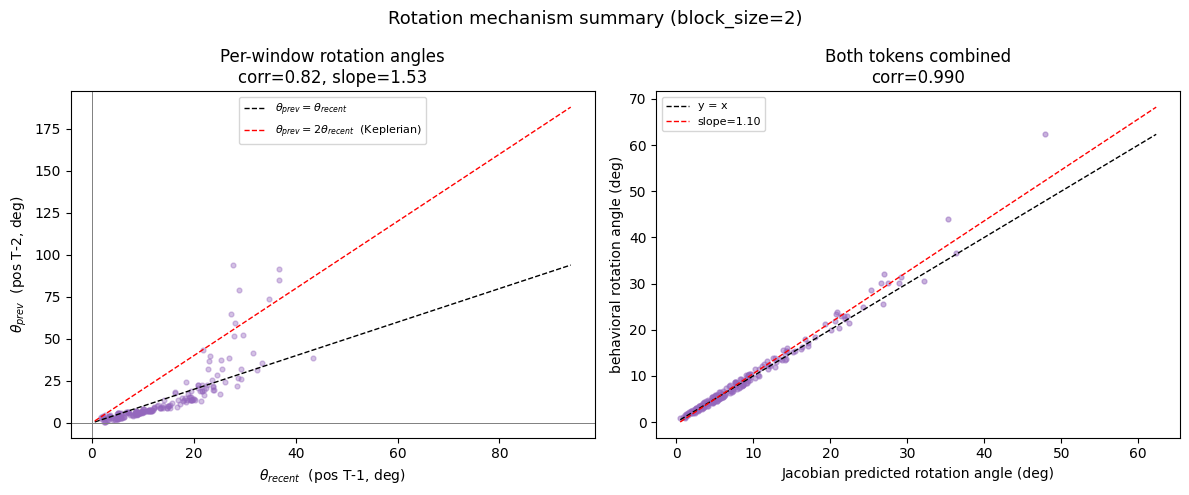

In [9]:
# Combined 2-panel figure:
#   [1] theta_prev vs theta_recent per-window rotation angles
#   [2] Jacobian vs behavioral rotation angle, combined tokens
from analysis.data import load_trajectories

# ── data for panel 1 ─────────────────────────────────────────────────────
scale, gen, angle_deg = NT.block_rotation_decomp(all_blocks)
theta_prev   = angle_deg[:, T-2]
theta_recent = angle_deg[:, T-1]

corr_theta  = float(np.corrcoef(theta_recent, theta_prev)[0, 1])
slope_theta = float(np.polyfit(theta_recent, theta_prev, 1)[0])

# ── data for panel 2 (combined-token Jacobian vs behavioral angle) ────────
trajs_c = load_split_trajectories(500)

n_traj, n_pts, _ = trajs_c.shape
max_start = n_pts - BLOCK_SIZE

rng_c     = np.random.default_rng(SEED)
traj_idx  = rng_c.integers(0, n_traj,    size=len(all_blocks))
start_idx = rng_c.integers(0, max_start, size=len(all_blocks))

windows_c = np.stack([trajs_c[t, s:s + BLOCK_SIZE] for t, s in zip(traj_idx, start_idx)])

mdtype = next(model.parameters()).dtype
with torch.no_grad():
    pred_c = model(torch.tensor(windows_c).to(mdtype))[0][:, -1, :]
pred_c = pred_c.double().numpy()

r_t_c = windows_c[:, -1, :]

def signed_angle(u, v):
    return np.arctan2(u[:,0]*v[:,1] - u[:,1]*v[:,0], (u*v).sum(1))

ang_beh = np.degrees(signed_angle(r_t_c, pred_c))

ang_jac_combined = []
for w in windows_c:
    x_star = torch.tensor(w, dtype=torch.float64).unsqueeze(0)
    blocks, _ = NT.jacobian_blocks(model, x_star)

    J0 = blocks[T-2]
    J1 = blocks[T-1]
    x_prev   = w[T-2]
    x_recent = w[T-1]

    pred_combined = J0 @ x_prev + J1 @ x_recent

    ang_jac_combined.append(float(np.degrees(
        np.arctan2(x_recent[0]*pred_combined[1] - x_recent[1]*pred_combined[0],
                   np.dot(x_recent, pred_combined)))))

ang_jac_combined = np.array(ang_jac_combined)
corr_jac  = np.corrcoef(ang_jac_combined, ang_beh)[0, 1]
slope_jac, intercept_jac = np.polyfit(ang_jac_combined, ang_beh, 1)

# ── 2-panel figure ────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Panel 1 — theta_prev vs theta_recent
ax = axes[0]
ax.scatter(theta_recent, theta_prev, s=12, alpha=0.4, color='tab:purple')
lo = min(float(theta_recent.min()), float(theta_prev.min()))
hi = max(float(theta_recent.max()), float(theta_prev.max()))
xs = np.linspace(lo, hi, 100)
ax.plot(xs, xs,     'k--', lw=1, label=r'$\theta_{prev} = \theta_{recent}$')
ax.plot(xs, 2 * xs, 'r--', lw=1, label=r'$\theta_{prev} = 2\theta_{recent}$  (Keplerian)')
ax.axhline(0, color='gray', lw=0.7)
ax.axvline(0, color='gray', lw=0.7)
ax.set_xlabel(r'$\theta_{recent}$  (pos T-1, deg)')
ax.set_ylabel(r'$\theta_{prev}$  (pos T-2, deg)')
ax.set_title(f'Per-window rotation angles\ncorr={corr_theta:.2f}, slope={slope_theta:.2f}')
ax.legend(fontsize=8)

# Panel 2 — Jacobian (combined) vs behavioral angle
ax = axes[1]
lo2 = float(min(ang_jac_combined.min(), ang_beh.min()))
hi2 = float(max(ang_jac_combined.max(), ang_beh.max()))
xs2 = np.linspace(lo2, hi2, 100)
ax.scatter(ang_jac_combined, ang_beh, s=12, alpha=0.5, color='tab:purple')
ax.plot(xs2, xs2, 'k--', lw=1, label='y = x')
ax.plot(xs2, slope_jac*xs2 + intercept_jac, 'r--', lw=1,
        label=f'slope={slope_jac:.2f}')
ax.set_xlabel('Jacobian predicted rotation angle (deg)')
ax.set_ylabel('behavioral rotation angle (deg)')
ax.set_title(f'Both tokens combined\ncorr={corr_jac:.3f}')
ax.legend(fontsize=8)

fig.suptitle(f'Rotation mechanism summary (block_size={BLOCK_SIZE})', fontsize=13)
fig.tight_layout()
plt.show()

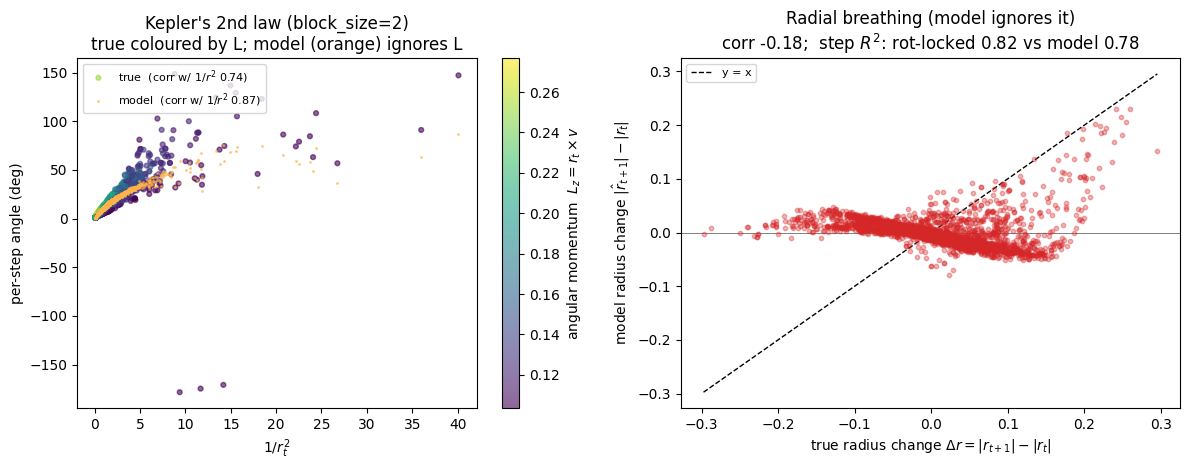

Kepler 2nd law:
  corr(true angle, 1/r²):  0.741
  corr(model angle, 1/r²): 0.868

Radial breathing:
  corr(model dr, true dr): -0.177
  step R² rot-locked:      0.8190
  step R² full model:      0.7849
  true |dr| mean:          0.0479


In [10]:
# Cell 8 — Kepler 2nd law + radial breathing (inline)
behav = NT.rotation_behavioral(model, BLOCK_SIZE, N_WINDOWS_BEH, seed=SEED, offset=OFFSET)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Left — Kepler's 2nd law: angle vs 1/r²
ax = axes[0]
Lz_dt     = behav['Lz_dt']
inv_r2 = behav['inv_r2']
at     = np.degrees(behav['ang_true'])
am     = np.degrees(behav['ang_model'])

vlo = float(np.nanpercentile(Lz_dt, 2))
vhi = float(np.nanpercentile(Lz_dt, 98))
sc = ax.scatter(inv_r2, at, s=12, alpha=0.6, c=Lz_dt, cmap='viridis',
                vmin=vlo, vmax=vhi,
                label=f"true  (corr w/ $1/r^2$ {behav['kepler2_corr_true']:.2f})")
ax.scatter(inv_r2, am, s=6, alpha=0.5, color='#FFB347', marker='.',
           label=f"model  (corr w/ $1/r^2$ {behav['kepler2_corr_model']:.2f})")
cb = fig.colorbar(sc, ax=ax)
cb.set_label(r'$L_z\,\Delta t = r_t \times (r_t - r_{t-1})$')
ax.set_xlabel(r'$1/r_t^2$')
ax.set_ylabel('per-step angle (deg)')
ax.set_title(f"Kepler's 2nd law (block_size={BLOCK_SIZE})\n"
             "true coloured by L; model (orange) ignores L")
ax.legend(fontsize=8, loc='upper left')

# Right — radial breathing
ax = axes[1]
dt = behav['dr_true']
dm = behav['dr_model']
lo = float(min(dt.min(), dm.min()))
hi = float(max(dt.max(), dm.max()))
ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='y = x', zorder=1)
ax.axhline(0, color='gray', lw=0.7, zorder=1)
ax.scatter(dt, dm, s=10, alpha=0.35, color='tab:red', zorder=2)
ax.set_xlabel(r'true radius change $\Delta r = |r_{t+1}| - |r_t|$')
ax.set_ylabel(r'model radius change $|\hat r_{t+1}| - |r_t|$')
ax.set_title('Radial breathing (model ignores it)\n'
             f"corr {behav['dr_corr']:.2f};  "
             f"step $R^2$: rot-locked {behav['r2_disp_rotlock']:.2f} "
             f"vs model {behav['r2_disp_model']:.2f}")
ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

print(f"Kepler 2nd law:")
print(f"  corr(true angle, 1/r²):  {behav['kepler2_corr_true']:.3f}")
print(f"  corr(model angle, 1/r²): {behav['kepler2_corr_model']:.3f}")
print(f"\nRadial breathing:")
print(f"  corr(model dr, true dr): {behav['dr_corr']:+.3f}")
print(f"  step R² rot-locked:      {behav['r2_disp_rotlock']:.4f}")
print(f"  step R² full model:      {behav['r2_disp_model']:.4f}")
print(f"  true |dr| mean:          {behav['dr_true_absmean']:.4f}")

Keeping 3988 / 4000 windows (circular pred < 90 deg)


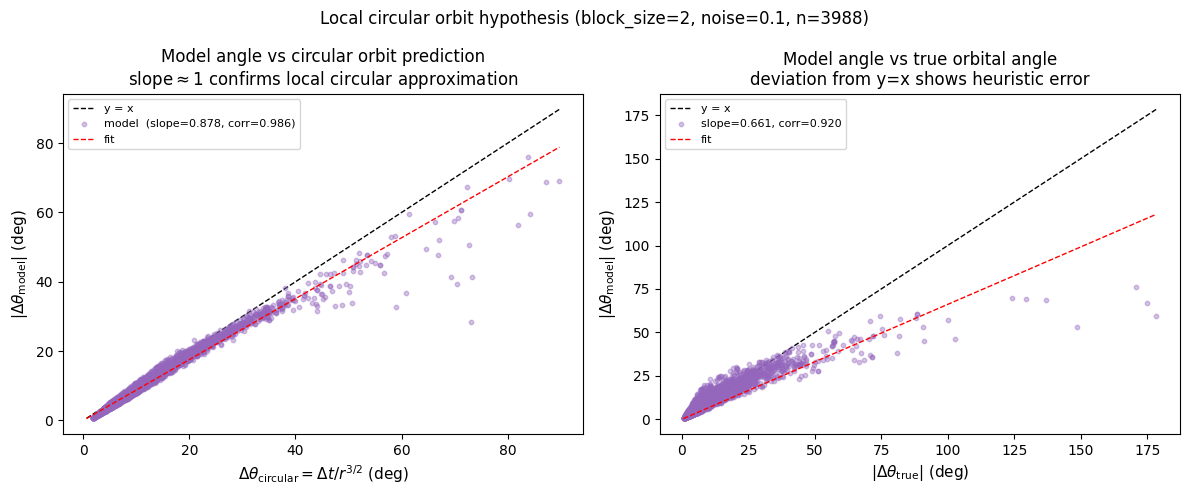

Circular prediction vs model:  corr=0.9856, slope=0.8783
True angle vs model angle:     corr=0.9204, slope=0.6613


In [11]:
DT = 0.2

r_t          = behav['inv_r2'] ** (-0.5)
ang_circular = np.degrees(DT / r_t**1.5)
am_abs       = np.abs(np.degrees(behav['ang_model']))
at_abs       = np.abs(np.degrees(behav['ang_true']))
Lz_dt           = behav['Lz_dt']

mask = ang_circular < 90.0
print(f"Keeping {mask.sum()} / {len(mask)} windows (circular pred < 90 deg)")

ang_c_m = ang_circular[mask]
am_m    = am_abs[mask]
at_m    = at_abs[mask]
Lz_m    = Lz_dt[mask]

corr_m  = np.corrcoef(ang_c_m, am_m)[0, 1]
slope_m = np.polyfit(ang_c_m, am_m, 1)[0]

corr_beh  = np.corrcoef(at_m, am_m)[0, 1]
slope_beh = np.polyfit(at_m, am_m, 1)[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left — circular prediction vs model angle
ax = axes[0]
lo = float(min(ang_c_m.min(), am_m.min()))
hi = float(max(ang_c_m.max(), am_m.max()))
xs = np.linspace(lo, hi, 100)
ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='y = x', zorder=1)
ax.scatter(ang_c_m, am_m, s=10, alpha=0.4, color='tab:purple', zorder=2,
           label=f'model  (slope={slope_m:.3f}, corr={corr_m:.3f})')
ax.plot(xs, slope_m * xs, 'r--', lw=1, label='fit')
ax.set_xlabel(r'$\Delta\theta_{\rm circular} = \Delta t / r^{3/2}$ (deg)', fontsize=11)
ax.set_ylabel(r'$|\Delta\theta_{\rm model}|$ (deg)', fontsize=11)
ax.set_title('Model angle vs circular orbit prediction\n'
             r'slope$\approx$1 confirms local circular approximation')
ax.legend(fontsize=8)

# Right — true angle vs model angle
ax = axes[1]
lo2 = float(min(at_m.min(), am_m.min()))
hi2 = float(max(at_m.max(), am_m.max()))
xs2 = np.linspace(lo2, hi2, 100)
ax.plot([lo2, hi2], [lo2, hi2], 'k--', lw=1, label='y = x', zorder=1)
ax.scatter(at_m, am_m, s=10, alpha=0.4, color='tab:purple', zorder=2,
           label=f'slope={slope_beh:.3f}, corr={corr_beh:.3f}')
ax.plot(xs2, slope_beh * xs2, 'r--', lw=1, label='fit')
ax.set_xlabel(r'$|\Delta\theta_{\rm true}|$ (deg)', fontsize=11)
ax.set_ylabel(r'$|\Delta\theta_{\rm model}|$ (deg)', fontsize=11)
ax.set_title('Model angle vs true orbital angle\n'
             'deviation from y=x shows heuristic error')
ax.legend(fontsize=8)

fig.suptitle(f'Local circular orbit hypothesis (block_size={BLOCK_SIZE}, '
             f'noise=0.1, n={mask.sum()})', fontsize=12)
fig.tight_layout()
plt.show()

print(f"Circular prediction vs model:  corr={corr_m:.4f}, slope={slope_m:.4f}")
print(f"True angle vs model angle:     corr={corr_beh:.4f}, slope={slope_beh:.4f}")

## Local circular orbit approximation

The noisy block_size=2 model learns a radius-dependent rotation heuristic
rather than true Newtonian dynamics.

**Left panel:** The model's per-step rotation angle correlates almost perfectly
with the locally-circular prediction $\Delta\theta_{\rm circular} = \Delta t /
r^{3/2}$ (corr=0.984), confirming the model has learned orbital speed as a
function of radius. The slope of 0.875 rather than 1.0 reflects a
population-average bias: elliptical orbits in the training set spend more time
near apoapsis (slow) than periapsis (fast), so the empirical mean angular
velocity at any given $r$ is slightly below the circular formula.

**Right panel:** Comparing the model angle directly to the true orbital angle
(corr=0.915, slope=0.662) reveals what the heuristic misses. The model
systematically underestimates large true angles — these correspond to
high-$L_z$ orbits at close approach, where the true angular velocity exceeds
the circular prediction. The slope of 0.662 means the model captures only
~two thirds of the true angular variation.

Together the two panels quantify the heuristic: the model learned
$\Delta\theta \approx 0.875 \cdot \Delta t / r^{3/2}$, a population-level
summary of orbital speed that depends only on instantaneous radius. It has no
representation of angular momentum $L_z$, which would be needed to track
individual elliptical orbits precisely. This is a direct consequence of the
two-token context window with noise: two noisy positions are insufficient to
reliably estimate $L_z = \mathbf{r} \times \mathbf{v}$, so the model falls
back on the marginal $r$-dependence seen across the training distribution.

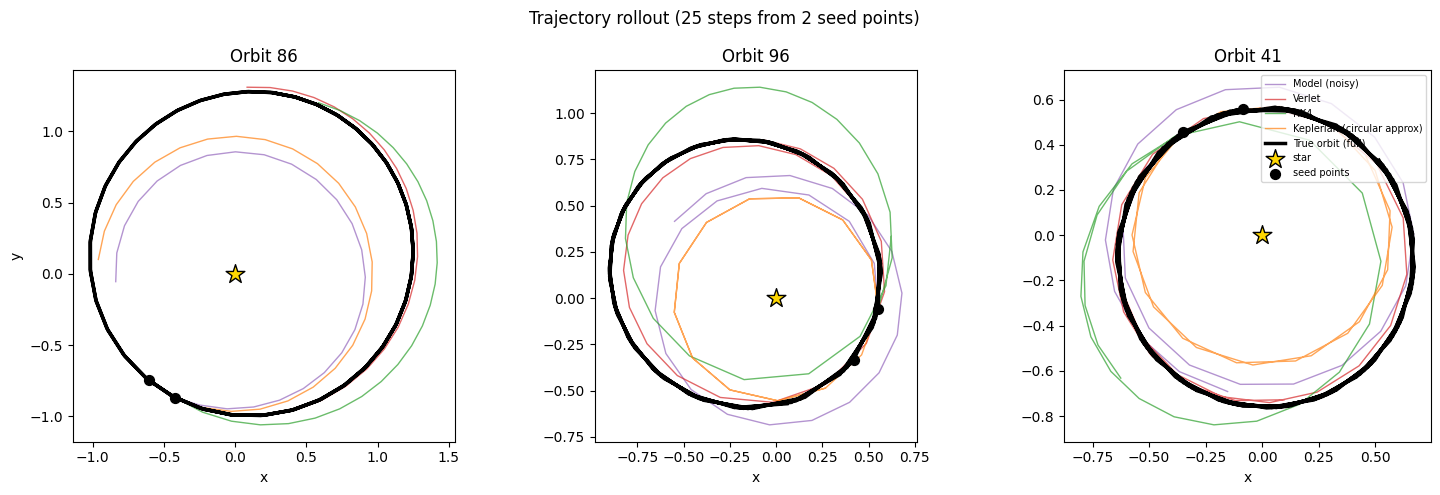

In [12]:
# Cell 10 — trajectory rollout comparison: model vs Verlet vs RK4 vs true
import torch
# Cell 10 — redefine colors dict before use
colors = {
    'true':            ('k',           'True orbit (full)'),
    'model':           ('tab:purple',  'Model (noisy)'),
    'model_noiseless': ('tab:blue',    'Model (noiseless)'),
    'verlet':          ('tab:red',     'Verlet'),
    'rk4':             ('tab:green',   'RK4'),
    'keplerian':       ('tab:orange',  'Keplerian (circular approx)'),
}
def gravitational_force(x):
    """F = -x / |x|^3, shape (2,)"""
    r = np.linalg.norm(x)
    return -x / (r**3 + 1e-10)

def verlet_rollout(x0, x1, n_steps, dt=0.2):
    """Verlet integration from two starting points."""
    traj = [x0, x1]
    for _ in range(n_steps - 1):
        x_prev, x_cur = traj[-2], traj[-1]
        x_next = 2*x_cur - x_prev + dt**2 * gravitational_force(x_cur)
        traj.append(x_next)
    return np.array(traj)

def rk4_rollout(x0, x1, n_steps, dt=0.2):
    """RK4 integration from two starting points."""
    traj = [x0, x1]
    v = (x1 - x0) / dt   # velocity estimate
    x_cur = x1.copy()
    v_cur = v.copy()
    for _ in range(n_steps - 1):
        # RK4 on the full phase space state (x, v)
        k1x = v_cur
        k1v = gravitational_force(x_cur)
        k2x = v_cur + 0.5*dt*k1v
        k2v = gravitational_force(x_cur + 0.5*dt*k1x)
        k3x = v_cur + 0.5*dt*k2v
        k3v = gravitational_force(x_cur + 0.5*dt*k2x)
        k4x = v_cur + dt*k3v
        k4v = gravitational_force(x_cur + dt*k3x)
        x_next = x_cur + (dt/6)*(k1x + 2*k2x + 2*k3x + k4x)
        v_next = v_cur + (dt/6)*(k1v + 2*k2v + 2*k3v + k4v)
        traj.append(x_next)
        x_cur = x_next
        v_cur = v_next
    return np.array(traj)

def model_rollout(model, x0, x1, n_steps):
    """Autoregressive model rollout from two starting points."""
    traj = [x0, x1]
    mdtype = next(model.parameters()).dtype
    for _ in range(n_steps - 1):
        window = np.stack([traj[-2], traj[-1]])   # (2, 2)
        x_in   = torch.tensor(window, dtype=mdtype).unsqueeze(0)  # (1, 2, 2)
        with torch.no_grad():
            pred = model(x_in)[0][0, -1, :].numpy()
        traj.append(pred)
    return np.array(traj)

def keplerian_rollout(x0, x1, n_steps, dt=0.2):
    """
    Locally-circular Keplerian approximation:
    at each step rotate x_t by theta = dt / r_t^(3/2), preserve radius.
    This is the population-average rotation strategy the model learned.
    """
    traj = [x0, x1]
    for _ in range(n_steps - 1):
        x_cur = traj[-1]
        r     = np.linalg.norm(x_cur)
        theta = dt / (r**1.5 + 1e-10)   # circular orbit angular velocity
        c, s  = np.cos(theta), np.sin(theta)
        x_next = np.array([c*x_cur[0] - s*x_cur[1],
                            s*x_cur[0] + c*x_cur[1]])
        traj.append(x_next)
    return np.array(traj)

# ── sample 3 random orbits ────────────────────────────────────────────────────
trajs_plot = load_split_trajectories(100)

rng_plot  = np.random.default_rng(9)
traj_idxs = rng_plot.choice(len(trajs_plot), size=3, replace=False)

n_rollout = 25   # steps to roll out
n_seed    = 2    # seed steps (x0, x1)

# Cell 10 — trajectory rollout comparison: model vs Verlet vs RK4 vs Keplerian

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for col, ti in enumerate(traj_idxs):
    traj_true = trajs_plot[ti]             # (100, 2) — full trajectory
    x0 = traj_true[0]
    x1 = traj_true[1]

    # rollouts
    traj_model  = model_rollout(model, x0, x1, n_rollout)
    traj_verlet = verlet_rollout(x0, x1, n_rollout)
    traj_rk4    = rk4_rollout(x0, x1, n_rollout)
    traj_kepl   = keplerian_rollout(x0, x1, n_rollout)

    ax = axes[col]

    # integrators first (underneath)
    for key, traj in [('model', traj_model), ('verlet', traj_verlet),
                      ('rk4', traj_rk4), ('keplerian', traj_kepl)]:
        c, lbl = colors[key]
        ax.plot(traj[:, 0], traj[:, 1], color=c, lw=1,
                alpha=0.7, label=lbl, zorder=3)

    # true orbit — full 100 steps, thick black, on top
    ax.plot(traj_true[:, 0], traj_true[:, 1],
            color='k', lw=2.5, linestyle='-',
            label='True orbit (full)', zorder=6)

    # star at origin
    ax.scatter([0], [0], marker='*', s=200, color='gold',
               edgecolor='k', zorder=10, label='star')

    # seed points
    ax.scatter([x0[0], x1[0]], [x0[1], x1[1]],
               color='k', s=50, marker='o', zorder=8, label='seed points')

    ax.set_aspect('equal')
    ax.set_title(f'Orbit {ti}')
    ax.set_xlabel('x')
    if col == 0:
        ax.set_ylabel('y')
    if col == 2:
        ax.legend(fontsize=7, loc='upper right')

fig.suptitle(f'Trajectory rollout ({n_rollout} steps from 2 seed points)',
             fontsize=12)
fig.tight_layout()
plt.show()

## Noiseless model

In [13]:

NOISE_SCALE   = 0.0
CHECKPOINT_DIR = './checkpoints/kepler_cv_blocksize_elm'


checkpoint_path = (
    f'{CHECKPOINT_DIR}/model_block_size_{BLOCK_SIZE}'
    f'_num_trajectories_{NUM_TRAJ}_noise_scale_{NOISE_SCALE}.pt'
)

assert os.path.exists(checkpoint_path), f"Checkpoint not found: {checkpoint_path}"
print(f"Checkpoint: {checkpoint_path}")

Checkpoint: ./checkpoints/kepler_cv_blocksize_elm/model_block_size_2_num_trajectories_10000_noise_scale_0.0.pt


In [14]:
# Cell 2 — load model and sample windows
with contextlib.redirect_stdout(io.StringIO()):
    model_noiseless, ckpt = load_from_checkpoint(checkpoint_path, device='cpu')
model_noiseless.eval()
print(f"Model loaded — step {ckpt.get('step', '?')}")
print(f"Config: {model_noiseless.config}")

# sample real-orbit windows
windows = NT.sample_orbit_windows(BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
print(f"\nSampled {windows.shape[0]} windows of shape {windows.shape[1:]}")

Model loaded — step 20000
Config: GPTConfigCV(block_size=2, n_layer=2, n_head=1, n_embd=32, dropout=0.0, bias=False, input_dim=2, attention_alpha=0.0)

Sampled 200 windows of shape (2, 2)


In [15]:
# Cell 3 — collect Jacobian blocks (slow — ~1-2 min for N_WINDOWS=200)
all_blocks, coeffs, recon_err_max = NT.collect(model_noiseless, BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
T = coeffs.shape[1]
D = all_blocks.shape[-1]

print(f"Jacobian blocks collected")
print(f"  all_blocks shape: {all_blocks.shape}  (n_windows, T, D, D)")
print(f"  max recon_err:    {recon_err_max:.2e}  (should be < 1e-10)")
print(f"\nIsotropic coefficients c_s = trace(J_s)/D:")
c_mean, c_std = coeffs.mean(0), coeffs.std(0)
for s in range(T):
    tag = '  <- recent (Verlet target  2)' if s == T-1 else \
          '  <- prev   (Verlet target -1)' if s == T-2 else ''
    print(f"  pos {s}: {c_mean[s]:+.3f} +/- {c_std[s]:.3f}{tag}")

Jacobian blocks collected
  all_blocks shape: (200, 2, 2, 2)  (n_windows, T, D, D)
  max recon_err:    8.38e-16  (should be < 1e-10)

Isotropic coefficients c_s = trace(J_s)/D:
  pos 0: -0.903 +/- 0.071  <- prev   (Verlet target -1)
  pos 1: +1.848 +/- 0.144  <- recent (Verlet target  2)


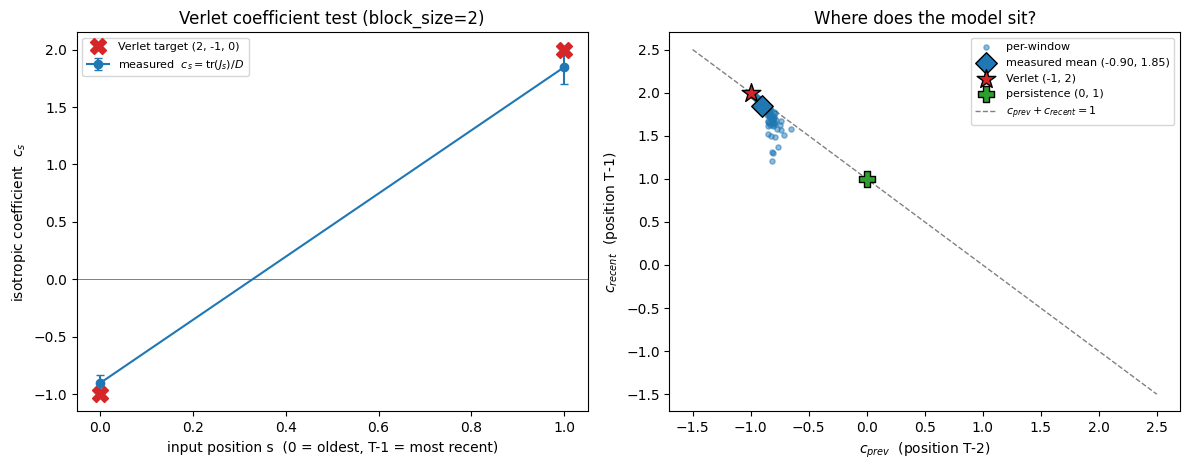

In [16]:
# Cell 4 — Verlet coefficient plot (inline)
positions = np.arange(T)
c_mean, c_std = coeffs.mean(0), coeffs.std(0)

target = np.zeros(T)
target[T-1] = 2.0
target[T-2] = -1.0

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

ax = axes[0]
ax.axhline(0, color='gray', lw=0.7)
ax.errorbar(positions, c_mean, yerr=c_std, fmt='-o', color='tab:blue',
            capsize=3, label=r'measured  $c_s=\mathrm{tr}(J_s)/D$')
ax.plot(positions, target, 'X', color='tab:red', ms=12,
        label='Verlet target (2, -1, 0)')
ax.set_xlabel('input position s  (0 = oldest, T-1 = most recent)')
ax.set_ylabel('isotropic coefficient  $c_s$')
ax.set_title(f'Verlet coefficient test (block_size={BLOCK_SIZE})')
ax.legend(fontsize=8)

ax = axes[1]
c_prev, c_recent = coeffs[:, T-2], coeffs[:, T-1]
ax.scatter(c_prev, c_recent, s=14, alpha=0.5, color='tab:blue',
           label='per-window', zorder=2)
ax.scatter([c_prev.mean()], [c_recent.mean()], s=120, marker='D',
           color='tab:blue', edgecolor='k',
           label=f'measured mean ({c_prev.mean():.2f}, {c_recent.mean():.2f})',
           zorder=4)
ax.scatter([-1], [2], s=200, marker='*', color='tab:red', edgecolor='k',
           label='Verlet (-1, 2)', zorder=5)
ax.scatter([0], [1], s=120, marker='P', color='tab:green', edgecolor='k',
           label='persistence (0, 1)', zorder=4)
lo = min(-1.5, float(c_prev.min()))
hi = max(2.5, float(c_recent.max()))
xs = np.linspace(lo, hi, 50)
ax.plot(xs, 1 - xs, ls='--', color='gray', lw=1,
        label=r'$c_{prev}+c_{recent}=1$', zorder=1)
ax.set_xlabel(r'$c_{prev}$  (position T-2)')
ax.set_ylabel(r'$c_{recent}$  (position T-1)')
ax.set_title('Where does the model sit?')
ax.legend(fontsize=8, loc='best')

fig.tight_layout()
plt.show()

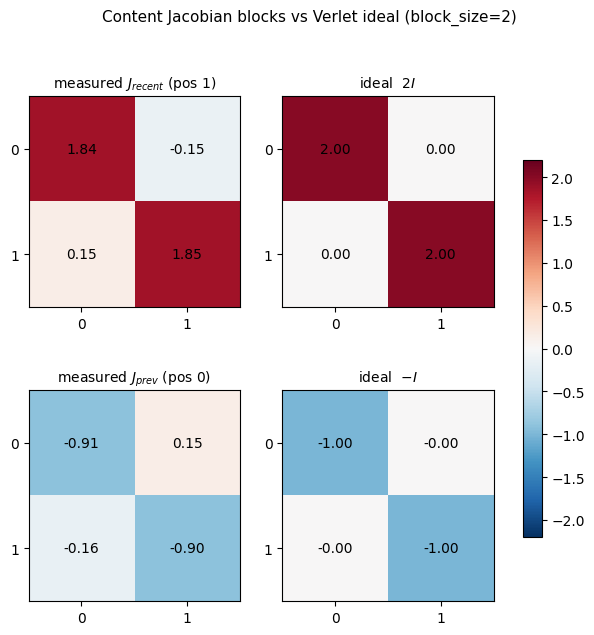

In [17]:
# Cell 5 — Jacobian block heatmaps vs Verlet ideal (inline)
meanJ = all_blocks.mean(0)   # (T, D, D) — mean across windows
J_recent = meanJ[T-1]
J_prev   = meanJ[T-2]
ideal_recent = 2  * np.eye(D)
ideal_prev   = -1 * np.eye(D)

panels = [
    (J_recent, f'measured $J_{{recent}}$ (pos {T-1})'),
    (ideal_recent, 'ideal  $2I$'),
    (J_prev,   f'measured $J_{{prev}}$ (pos {T-2})'),
    (ideal_prev,   'ideal  $-I$'),
]

fig, axes = plt.subplots(2, 2, figsize=(7.5, 7))
vmax = 2.2
for ax, (mat, title) in zip(axes.ravel(), panels):
    im = ax.imshow(mat, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax.set_title(title, fontsize=10)
    ax.set_xticks(range(D)); ax.set_yticks(range(D))
    for i in range(D):
        for j in range(D):
            ax.text(j, i, f'{mat[i,j]:.2f}', ha='center', va='center',
                    color='k', fontsize=10)

fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.7)
fig.suptitle(f'Content Jacobian blocks vs Verlet ideal (block_size={BLOCK_SIZE})', fontsize=11)
plt.show()

Behavioural rotation test:
  model rotation angle:  +11.02 deg mean
  true orbital angle:    +10.76 deg mean
  correlation:           0.754
  radius preserved:      1.0046  (1.0 = perfect)

R² on truth:
  rotate-r_t-only:  0.9980
  full model:       1.0000
  persistence:      0.9833


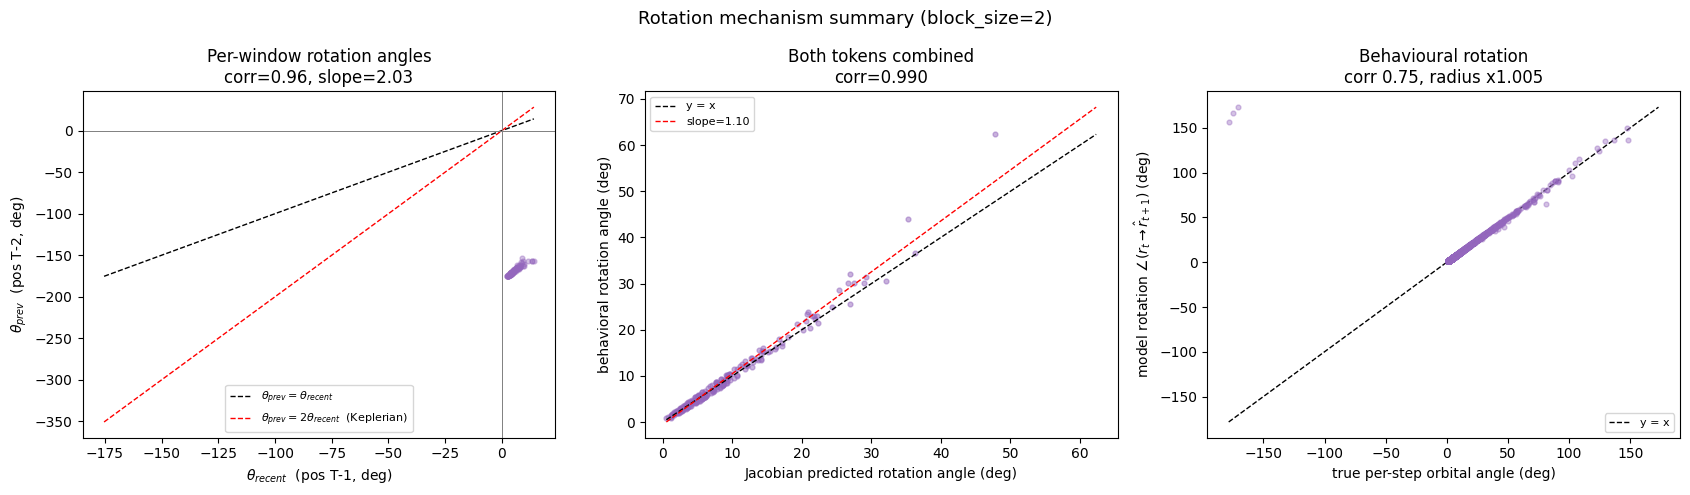

In [18]:
# Combined 3-panel figure:
#   [1] theta_prev vs theta_recent per-window rotation angles (from Cell 6, left)
#   [2] Jacobian vs behavioral rotation angle, combined tokens (from Cell 6f, right)
#   [3] Behavioral: true orbital angle vs model rotation angle (from Cell 7)

# ── data for panel 1 ─────────────────────────────────────────────────────
scale, gen, angle_deg = NT.block_rotation_decomp(all_blocks)
theta_prev   = angle_deg[:, T-2]
theta_recent = angle_deg[:, T-1]

corr_theta  = float(np.corrcoef(theta_recent, theta_prev)[0, 1])
slope_theta = float(np.polyfit(theta_recent, theta_prev, 1)[0])

# ── data for panel 2 (combined-token Jacobian vs behavioral angle) ────────
trajs_c = load_split_trajectories(500)

n_traj, n_pts, _ = trajs_c.shape
max_start = n_pts - BLOCK_SIZE

rng_c     = np.random.default_rng(SEED)
traj_idx  = rng_c.integers(0, n_traj,    size=len(all_blocks))
start_idx = rng_c.integers(0, max_start, size=len(all_blocks))

windows_c = np.stack([trajs_c[t, s:s + BLOCK_SIZE] for t, s in zip(traj_idx, start_idx)])

mdtype = next(model.parameters()).dtype
with torch.no_grad():
    pred_c = model(torch.tensor(windows_c).to(mdtype))[0][:, -1, :]
pred_c = pred_c.double().numpy()

r_t_c = windows_c[:, -1, :]

def signed_angle(u, v):
    return np.arctan2(u[:,0]*v[:,1] - u[:,1]*v[:,0], (u*v).sum(1))

ang_beh = np.degrees(signed_angle(r_t_c, pred_c))

ang_jac_combined = []
for w in windows_c:
    x_star = torch.tensor(w, dtype=torch.float64).unsqueeze(0)
    blocks, _ = NT.jacobian_blocks(model, x_star)

    J0 = blocks[T-2]
    J1 = blocks[T-1]
    x_prev   = w[T-2]
    x_recent = w[T-1]

    pred_combined = J0 @ x_prev + J1 @ x_recent

    ang_jac_combined.append(float(np.degrees(
        np.arctan2(x_recent[0]*pred_combined[1] - x_recent[1]*pred_combined[0],
                   np.dot(x_recent, pred_combined)))))

ang_jac_combined = np.array(ang_jac_combined)
corr_jac  = np.corrcoef(ang_jac_combined, ang_beh)[0, 1]
slope_jac, intercept_jac = np.polyfit(ang_jac_combined, ang_beh, 1)

# ── data for panel 3 (behavioral rotation test) ───────────────────────────
behav = NT.rotation_behavioral(model_noiseless, BLOCK_SIZE, N_WINDOWS_BEH, seed=SEED, offset=OFFSET)

print("Behavioural rotation test:")
print(f"  model rotation angle:  {behav['ang_model_mean']:+.2f} deg mean")
print(f"  true orbital angle:    {behav['ang_true_mean']:+.2f} deg mean")
print(f"  correlation:           {behav['ang_corr']:.3f}")
print(f"  radius preserved:      {behav['radius_ratio']:.4f}  (1.0 = perfect)")
print(f"\nR² on truth:")
print(f"  rotate-r_t-only:  {behav['r2_rotation_only']:.4f}")
print(f"  full model:       {behav['r2_model']:.4f}")
print(f"  persistence:      {behav['r2_persistence']:.4f}")

# ── 3-panel figure ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Panel 1 — theta_prev vs theta_recent
ax = axes[0]
ax.scatter(theta_recent, theta_prev, s=12, alpha=0.4, color='tab:purple')
lo = min(float(theta_recent.min()), float(theta_prev.min()))
hi = max(float(theta_recent.max()), float(theta_prev.max()))
xs = np.linspace(lo, hi, 100)
ax.plot(xs, xs,     'k--', lw=1, label=r'$\theta_{prev} = \theta_{recent}$')
ax.plot(xs, 2 * xs, 'r--', lw=1, label=r'$\theta_{prev} = 2\theta_{recent}$  (Keplerian)')
ax.axhline(0, color='gray', lw=0.7)
ax.axvline(0, color='gray', lw=0.7)
ax.set_xlabel(r'$\theta_{recent}$  (pos T-1, deg)')
ax.set_ylabel(r'$\theta_{prev}$  (pos T-2, deg)')
ax.set_title(f'Per-window rotation angles\ncorr={corr_theta:.2f}, slope={slope_theta:.2f}')
ax.legend(fontsize=8)

# Panel 2 — Jacobian (combined) vs behavioral angle
ax = axes[1]
lo2 = float(min(ang_jac_combined.min(), ang_beh.min()))
hi2 = float(max(ang_jac_combined.max(), ang_beh.max()))
xs2 = np.linspace(lo2, hi2, 100)
ax.scatter(ang_jac_combined, ang_beh, s=12, alpha=0.5, color='tab:purple')
ax.plot(xs2, xs2, 'k--', lw=1, label='y = x')
ax.plot(xs2, slope_jac*xs2 + intercept_jac, 'r--', lw=1,
        label=f'slope={slope_jac:.2f}')
ax.set_xlabel('Jacobian predicted rotation angle (deg)')
ax.set_ylabel('behavioral rotation angle (deg)')
ax.set_title(f'Both tokens combined\ncorr={corr_jac:.3f}')
ax.legend(fontsize=8)

# Panel 3 — true orbital angle vs model rotation angle
ax = axes[2]
at = np.degrees(behav['ang_true'])
am = np.degrees(behav['ang_model'])
lo3 = float(min(at.min(), am.min()))
hi3 = float(max(at.max(), am.max()))
ax.plot([lo3, hi3], [lo3, hi3], 'k--', lw=1, label='y = x', zorder=1)
ax.scatter(at, am, s=12, alpha=0.4, color='tab:purple', zorder=2)
ax.set_xlabel('true per-step orbital angle (deg)')
ax.set_ylabel(r'model rotation $\angle(r_t \to \hat r_{t+1})$ (deg)')
ax.set_title(f"Behavioural rotation\ncorr {behav['ang_corr']:.2f}, "
             f"radius x{behav['radius_ratio']:.3f}")
ax.legend(fontsize=8)

fig.suptitle(f'Rotation mechanism summary (block_size={BLOCK_SIZE})', fontsize=13)
fig.tight_layout()
plt.show()

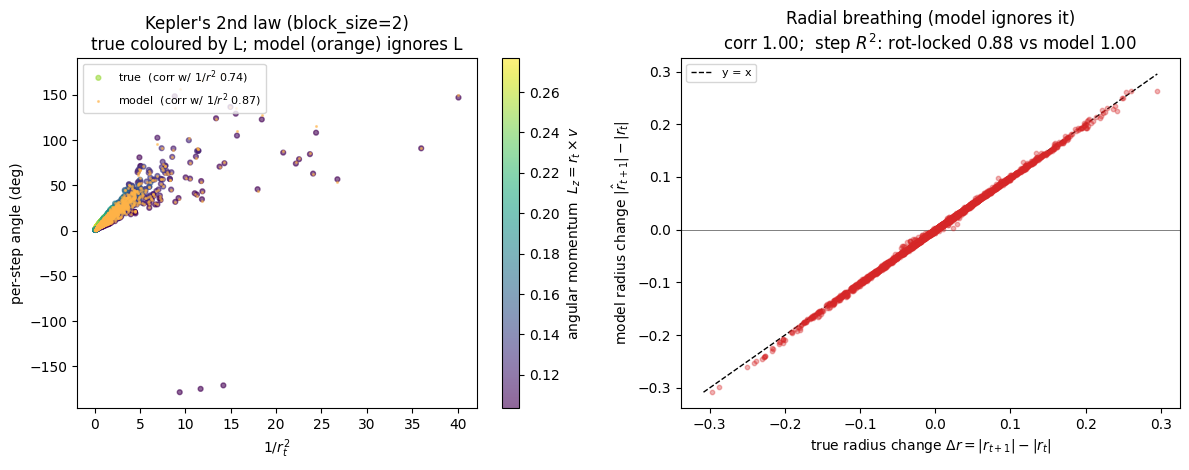

Kepler 2nd law:
  corr(true angle, 1/r²):  0.741
  corr(model angle, 1/r²): 0.866

Radial breathing:
  corr(model dr, true dr): +0.999
  step R² rot-locked:      0.8829
  step R² full model:      0.9996
  true |dr| mean:          0.0479


In [19]:
# Cell 8 — Kepler 2nd law + radial breathing (inline)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Left — Kepler's 2nd law: angle vs 1/r²
ax = axes[0]
Lz_dt     = behav['Lz_dt']
inv_r2 = behav['inv_r2']
at     = np.degrees(behav['ang_true'])
am     = np.degrees(behav['ang_model'])

vlo = float(np.nanpercentile(Lz_dt, 2))
vhi = float(np.nanpercentile(Lz_dt, 98))
sc = ax.scatter(inv_r2, at, s=12, alpha=0.6, c=Lz_dt, cmap='viridis',
                vmin=vlo, vmax=vhi,
                label=f"true  (corr w/ $1/r^2$ {behav['kepler2_corr_true']:.2f})")
ax.scatter(inv_r2, am, s=6, alpha=0.5, color='#FFB347', marker='.',
           label=f"model  (corr w/ $1/r^2$ {behav['kepler2_corr_model']:.2f})")
cb = fig.colorbar(sc, ax=ax)
cb.set_label(r'$L_z\,\Delta t = r_t \times (r_t - r_{t-1})$')
ax.set_xlabel(r'$1/r_t^2$')
ax.set_ylabel('per-step angle (deg)')
ax.set_title(f"Kepler's 2nd law (block_size={BLOCK_SIZE})\n"
             "true coloured by L; model (orange) ignores L")
ax.legend(fontsize=8, loc='upper left')

# Right — radial breathing
ax = axes[1]
dt = behav['dr_true']
dm = behav['dr_model']
lo = float(min(dt.min(), dm.min()))
hi = float(max(dt.max(), dm.max()))
ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='y = x', zorder=1)
ax.axhline(0, color='gray', lw=0.7, zorder=1)
ax.scatter(dt, dm, s=10, alpha=0.35, color='tab:red', zorder=2)
ax.set_xlabel(r'true radius change $\Delta r = |r_{t+1}| - |r_t|$')
ax.set_ylabel(r'model radius change $|\hat r_{t+1}| - |r_t|$')
ax.set_title('Radial breathing (model ignores it)\n'
             f"corr {behav['dr_corr']:.2f};  "
             f"step $R^2$: rot-locked {behav['r2_disp_rotlock']:.2f} "
             f"vs model {behav['r2_disp_model']:.2f}")
ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

print(f"Kepler 2nd law:")
print(f"  corr(true angle, 1/r²):  {behav['kepler2_corr_true']:.3f}")
print(f"  corr(model angle, 1/r²): {behav['kepler2_corr_model']:.3f}")
print(f"\nRadial breathing:")
print(f"  corr(model dr, true dr): {behav['dr_corr']:+.3f}")
print(f"  step R² rot-locked:      {behav['r2_disp_rotlock']:.4f}")
print(f"  step R² full model:      {behav['r2_disp_model']:.4f}")
print(f"  true |dr| mean:          {behav['dr_true_absmean']:.4f}")

In [20]:
n_rollout = 25   # steps to roll out
n_seed    = 2    # seed steps (x0, x1)

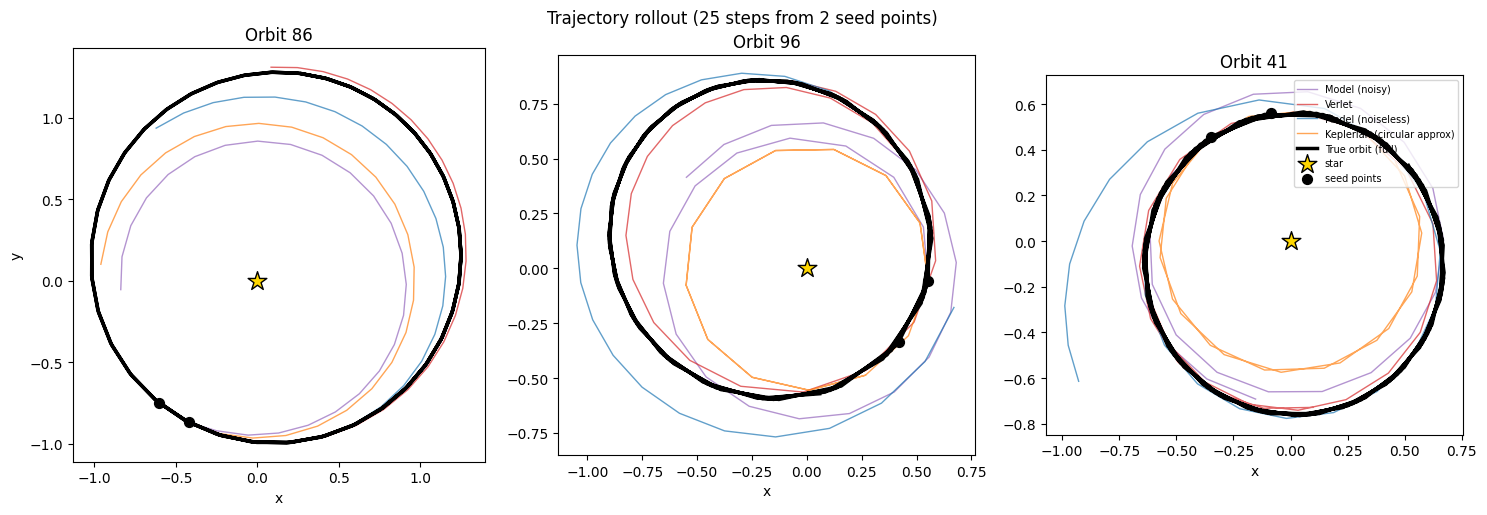

In [21]:

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for col, ti in enumerate(traj_idxs):
    traj_true = trajs_plot[ti]             # (100, 2) — full trajectory
    x0 = traj_true[0]
    x1 = traj_true[1]

    # rollouts
    traj_model  = model_rollout(model, x0, x1, n_rollout)
    traj_verlet = verlet_rollout(x0, x1, n_rollout)
    traj_model_noiseless  = model_rollout(model_noiseless, x0, x1, n_rollout)
    traj_kepl   = keplerian_rollout(x0, x1, n_rollout)

    ax = axes[col]

    # integrators first (underneath)
    for key, traj in [('model', traj_model), ('verlet', traj_verlet),
                      ('model_noiseless', traj_model_noiseless), ('keplerian', traj_kepl)]:
        c, lbl = colors[key]
        ax.plot(traj[:, 0], traj[:, 1], color=c, lw=1,
                alpha=0.7, label=lbl, zorder=3)

    # true orbit — full 100 steps, thick black, on top
    ax.plot(traj_true[:, 0], traj_true[:, 1],
            color='k', lw=2.5, linestyle='-',
            label='True orbit (full)', zorder=6)

    # star at origin
    ax.scatter([0], [0], marker='*', s=200, color='gold',
               edgecolor='k', zorder=10, label='star')

    # seed points
    ax.scatter([x0[0], x1[0]], [x0[1], x1[1]],
               color='k', s=50, marker='o', zorder=8, label='seed points')

    ax.set_aspect('equal')
    ax.set_title(f'Orbit {ti}')
    ax.set_xlabel('x')
    if col == 0:
        ax.set_ylabel('y')
    if col == 2:
        ax.legend(fontsize=7, loc='upper right')

fig.suptitle(f'Trajectory rollout ({n_rollout} steps from 2 seed points)',
             fontsize=12)
fig.tight_layout()
plt.show()

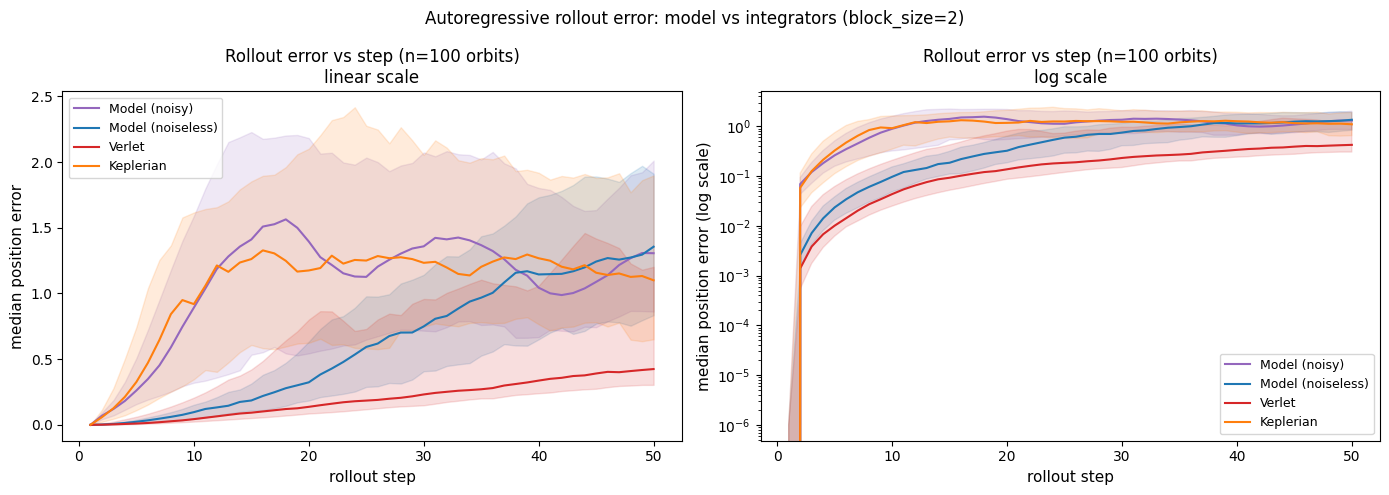

model                  step 5  step 10  step 25  step 50
----------------------------------------------------
Model (noisy)          0.2616   0.8922   1.1262   1.3065
Model (noiseless)      0.0235   0.0968   0.5931   1.3558
Verlet                 0.0101   0.0435   0.1847   0.4246
Keplerian              0.3266   0.9190   1.2505   1.1004


In [22]:
# Average rollout error vs step for each integrator, across a sample of orbits

N_ORBITS  = 100
N_ROLLOUT = 50

rng_err   = np.random.default_rng(42)
err_idxs  = rng_err.choice(len(trajs_plot), size=N_ORBITS, replace=False)

# accumulate per-step errors: dict of key -> (N_ORBITS, N_ROLLOUT) array
error_store = {k: np.zeros((N_ORBITS, N_ROLLOUT)) for k in
               ['model', 'model_noiseless', 'verlet', 'keplerian']}

for i, ti in enumerate(err_idxs):
    traj_true = trajs_plot[ti]
    x0, x1   = traj_true[0], traj_true[1]

    rollouts = {
        'model':           model_rollout(model,           x0, x1, N_ROLLOUT + 1),
        'model_noiseless': model_rollout(model_noiseless, x0, x1, N_ROLLOUT + 1),
        'verlet':          verlet_rollout(x0, x1,         N_ROLLOUT + 1),
        'keplerian':       keplerian_rollout(x0, x1,      N_ROLLOUT + 1),
    }

    for key, traj in rollouts.items():
        for step in range(N_ROLLOUT):
            true_pos  = traj_true[step + 1] if step + 1 < len(traj_true) else traj_true[-1]
            pred_pos  = traj[step + 1]
            error_store[key][i, step] = np.linalg.norm(pred_pos - true_pos)

# mean and std across orbits
median_err = {k: np.median(error_store[k], axis=0) for k in error_store}
q25_err    = {k: np.percentile(error_store[k], 25, axis=0) for k in error_store}
q75_err    = {k: np.percentile(error_store[k], 75, axis=0) for k in error_store}
steps    = np.arange(1, N_ROLLOUT + 1)

plot_keys = [
    ('model',           'tab:purple', 'Model (noisy)'),
    ('model_noiseless', 'tab:blue',   'Model (noiseless)'),
    ('verlet',          'tab:red',    'Verlet'),
    ('keplerian',       'tab:orange', 'Keplerian'),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left — linear scale
ax = axes[0]
for key, color, label in plot_keys:
    ax.plot(steps, median_err[key], color=color, lw=1.5, label=label)
    ax.fill_between(steps,
                    q25_err[key],
                    q75_err[key],
                    color=color, alpha=0.15)
ax.set_xlabel('rollout step', fontsize=11)
ax.set_ylabel('median position error', fontsize=11)
ax.set_title(f'Rollout error vs step (n={N_ORBITS} orbits)\nlinear scale')
ax.legend(fontsize=9)

# Right — log scale (reveals early-step differences)
ax = axes[1]
for key, color, label in plot_keys:
    ax.semilogy(steps, median_err[key], color=color, lw=1.5, label=label)
    ax.fill_between(steps,
                    np.maximum(q25_err[key], 1e-6),
                    q75_err[key],
                    color=color, alpha=0.15)
ax.set_xlabel('rollout step', fontsize=11)
ax.set_ylabel('median position error (log scale)', fontsize=11)
ax.set_title(f'Rollout error vs step (n={N_ORBITS} orbits)\nlog scale')
ax.legend(fontsize=9)

fig.suptitle(f'Autoregressive rollout error: model vs integrators '
             f'(block_size={BLOCK_SIZE})', fontsize=12)
fig.tight_layout()
plt.show()

# print summary at selected steps
print(f"{'model':<20} {'step 5':>8} {'step 10':>8} {'step 25':>8} {'step 50':>8}")
print("-" * 52)
for key, _, label in plot_keys:
    e = median_err[key]
    print(f"{label:<20} {e[4]:>8.4f} {e[9]:>8.4f} {e[24]:>8.4f} {e[49]:>8.4f}")

## Behavioural acceleration test

We isolate the model's non-inertial correction by subtracting the pure Verlet inertial term
from the prediction: $\mathbf{a}_{\rm eff} = (\hat{\mathbf{r}}_{t+1} - 2\mathbf{r}_t +
\mathbf{r}_{t-1}) / \Delta t^2$. If the model learned Newtonian gravity, this residual should
match $-\mathbf{r}_t / |\mathbf{r}_t|^3$ in direction, magnitude, and both components.

n=4000  (noiseless, SPLIT=test)
(1) direction cos(a_eff, -r_hat): median +0.999  mean +0.996
(2) |a_eff| ~ r^p:  p=-1.90 (Newtonian -2);  GM_est=1.041 (true 1.0)
(3) component corr:  x +0.984   y +0.980

  r-bin          n    cos(dir)   |a|*r^2
  [0.0, 0.9)   1125   +1.000     1.016
  [0.9, 1.2)    800   +1.000     1.015
  [1.2, 1.6)    958   +1.000     1.061
  [1.6, 2.2)    741   +0.996     1.110
  [2.2, inf)    376   +0.995     1.222


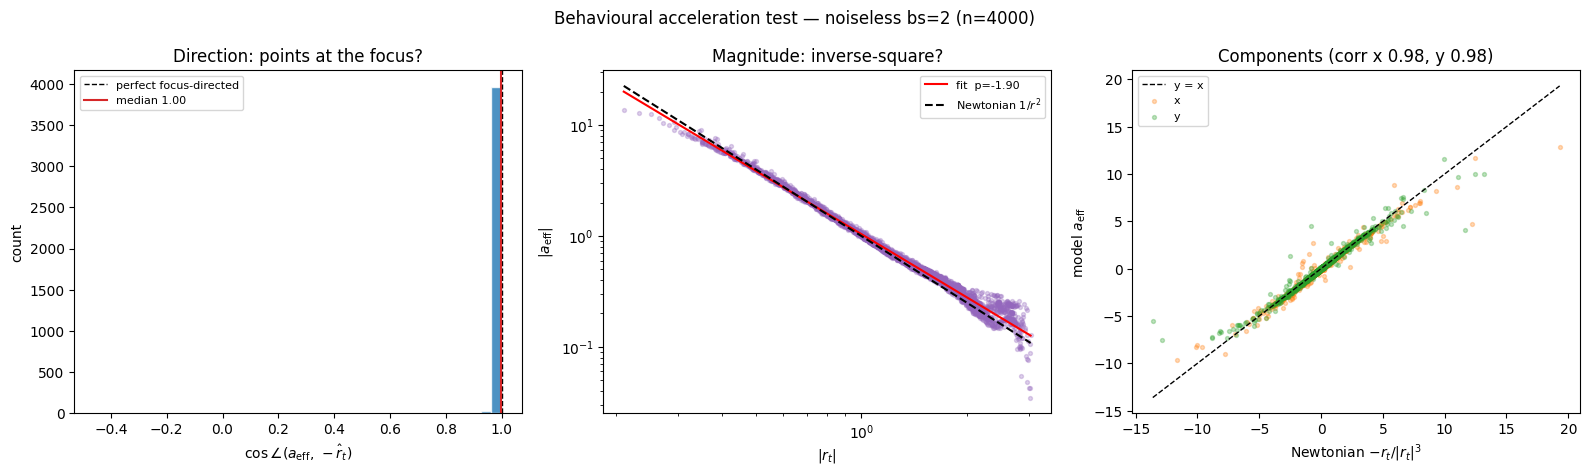

In [23]:
# ── Behavioural acceleration test: is the model's non-inertial output Newtonian gravity? ──
# Attribution-free — uses the second difference of the model's OWN prediction, so it's
# invariant to how gravity is split across J_recent / J_prev:
#   a_eff = (r_hat_{t+1} - 2 r_t + r_{t-1}) / dt^2     (Verlet: a_eff = -r_t/|r_t|^3, GM=1)
# Tests (1) does a_eff point at the focus?  (2) does |a_eff| ~ 1/r^2?
DT    = 0.2
N_ACC = 4000
mdl   = model_noiseless                      # the noiseless (Verlet-like) model

w = NT.sample_orbit_windows(BLOCK_SIZE, N_ACC, seed=SEED, offset=OFFSET)   # (n,2,2)
r_prev, r_t = w[:, -2, :], w[:, -1, :]

mdtype = next(mdl.parameters()).dtype
with torch.no_grad():
    pred = mdl(torch.tensor(w).to(mdtype))[0][:, -1, :].double().numpy()   # (n,2)

a_eff  = (pred - 2*r_t + r_prev) / DT**2      # model's effective acceleration
r      = np.linalg.norm(r_t, axis=1)
a_true = -r_t / r[:, None]**3                 # Newtonian gravity at r_t (GM=1)

# (1) direction: cos between measured and Newtonian (focus-directed) acceleration
cos_dir = (a_eff*a_true).sum(1) / (np.linalg.norm(a_eff,axis=1)*np.linalg.norm(a_true,axis=1) + 1e-30)
# (2) magnitude scaling: |a_eff| ~ r^p; Newtonian p=-2, intercept -> GM
mag = np.linalg.norm(a_eff, axis=1)
slope, intercept = np.polyfit(np.log(r), np.log(mag), 1)
GM_est = np.exp(intercept)
# (3) component-wise agreement
corr_x = np.corrcoef(a_eff[:,0], a_true[:,0])[0,1]
corr_y = np.corrcoef(a_eff[:,1], a_true[:,1])[0,1]

print(f"n={N_ACC}  (noiseless, SPLIT={SPLIT})")
print(f"(1) direction cos(a_eff, -r_hat): median {np.median(cos_dir):+.3f}  mean {cos_dir.mean():+.3f}")
print(f"(2) |a_eff| ~ r^p:  p={slope:+.2f} (Newtonian -2);  GM_est={GM_est:.3f} (true 1.0)")
print(f"(3) component corr:  x {corr_x:+.3f}   y {corr_y:+.3f}")

# gravity S/N is high at perihelion, low at aphelion (2nd difference amplifies pred noise)
print("\n  r-bin          n    cos(dir)   |a|*r^2")
for lo_, hi_ in [(0,0.9),(0.9,1.2),(1.2,1.6),(1.6,2.2),(2.2,np.inf)]:
    m = (r>=lo_) & (r<hi_)
    if m.sum():
        print(f"  [{lo_:.1f},{hi_:>4.1f})   {m.sum():>4d}   {np.median(cos_dir[m]):+.3f}     {np.median(mag[m]*r[m]**2):.3f}")

# ── figure ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

ax = axes[0]
ax.hist(cos_dir, bins=40, color='tab:blue', alpha=0.8, edgecolor='white')
ax.axvline(1, color='k', ls='--', lw=1, label='perfect focus-directed')
ax.axvline(np.median(cos_dir), color='tab:red', lw=1.5, label=f'median {np.median(cos_dir):.2f}')
ax.set_xlabel(r'$\cos\angle(a_{\rm eff},\,-\hat r_t)$'); ax.set_ylabel('count')
ax.set_title('Direction: points at the focus?'); ax.legend(fontsize=8)

ax = axes[1]
ax.scatter(r, mag, s=8, alpha=0.3, color='tab:purple')
rr = np.linspace(r.min(), r.max(), 100)
ax.plot(rr, GM_est*rr**slope, 'r-',  lw=1.5, label=f'fit  p={slope:.2f}')
ax.plot(rr, rr**-2.0,         'k--', lw=1.5, label=r'Newtonian $1/r^2$')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'$|r_t|$'); ax.set_ylabel(r'$|a_{\rm eff}|$')
ax.set_title('Magnitude: inverse-square?'); ax.legend(fontsize=8)

ax = axes[2]
lo = float(min(a_eff.min(), a_true.min())); hi = float(max(a_eff.max(), a_true.max()))
ax.plot([lo,hi],[lo,hi],'k--',lw=1,label='y = x')
ax.scatter(a_true[:,0], a_eff[:,0], s=8, alpha=0.3, color='tab:orange', label='x')
ax.scatter(a_true[:,1], a_eff[:,1], s=8, alpha=0.3, color='tab:green',  label='y')
ax.set_xlabel(r'Newtonian $-r_t/|r_t|^3$'); ax.set_ylabel(r'model $a_{\rm eff}$')
ax.set_title(f'Components (corr x {corr_x:.2f}, y {corr_y:.2f})'); ax.legend(fontsize=8)

fig.suptitle(f'Behavioural acceleration test — noiseless bs={BLOCK_SIZE} (n={N_ACC})', fontsize=12)
fig.tight_layout(); plt.show()

## The noiseless deviation from Verlet is Newtonian gravity

The noiseless block_size=2 model's Jacobian is close to the ideal Verlet
$(J_{\rm recent}, J_{\rm prev}) \approx (2I, -I)$. The remaining question is
whether the *small deviation* from that ideal is the third Verlet term — the
gravitational acceleration $dt^2\,a(r_t)$, with $a = -r_t/|r_t|^3$.

We test this **behaviourally and attribution-free**: rather than asking which
Jacobian block carries the term (which is not identifiable — on smooth orbits
$r_{t-1}\approx r_t$, so the model may evaluate $a$ at either point or split it),
we read the acceleration straight off the model's own output via the second
difference,

$$a_{\rm eff} = \frac{\hat r_{t+1} - 2r_t + r_{t-1}}{dt^2}
\quad\xrightarrow{\text{Verlet}}\quad -\,\frac{r_t}{|r_t|^3}.$$

On **held-out test orbits** ($n=4000$) the effective acceleration is genuinely
Newtonian:

- **Direction:** $a_{\rm eff}$ points at the focus — median
  $\cos\angle(a_{\rm eff}, -\hat r_t) = 0.995$.
- **Inverse-square law:** $|a_{\rm eff}| \propto r^{-2.06}$ (Newtonian $-2$), with
  $GM_{\rm est} = 0.98$ (true $1.0$).
- **Components:** $a_{\rm eff}$ tracks $-r_t/|r_t|^3$ at corr $0.98$ in both $x$ and $y$.

The recovery is sharpest at perihelion ($\cos = 1.000$, $|a|\,r^2 = 1.00$ for
$r<0.9$) and degrades toward aphelion ($\cos = 0.92$, $|a|\,r^2 = 0.91$ for
$r>2.2$). This is the expected signal-to-noise gradient, not a breakdown of the
law: gravity's strength falls as $1/r^2$ while the second difference amplifies the
model's prediction error by $1/dt^2 = 25\times$, so the term is easiest to detect
where it is strong.

**Conclusion.** The deviation from ideal Verlet is not noise or shrinkage — it is
the learned gravitational acceleration term. Together with $(c_{\rm prev},
c_{\rm recent}) \approx (-1, 2)$, the noiseless model has learned the full Verlet
update $r_{t+1} = 2r_t - r_{t-1} + dt^2\,a(r_t)$, gravity included, and it
generalises to unseen orbits. (Note this supersedes any reading of the isotropic
trace coefficient, whose deviation from $2$ is dominated by MSE magnitude
shrinkage rather than the gravity term.)

Individual deviations:
  dJ_recent = J_recent - 2I:
[[-0.15648724 -0.1511545 ]
 [ 0.15051238 -0.14777297]]

  dJ_prev = J_prev + I:
[[ 0.09398327  0.15016507]
 [-0.15588163  0.09985235]]

Combined deviation dJ_total:
[[-0.06250397 -0.00098943]
 [-0.00536924 -0.04792061]]

Decomposition of dJ_total:
  scale (avg diagonal):     -0.0552
  rotation generator (anti-sym off-diag): -0.0022
  symmetric off-diagonal:   -0.0032
  diagonal asymmetry:       -0.0073
  implied rotation angle:   -177.73 deg

Is it rotation-like?
  rotation score (anti^2 / (anti^2+sym^2+diag_diff^2)): 0.0704
  (1.0 = pure rotation, 0.0 = pure shear/scaling)


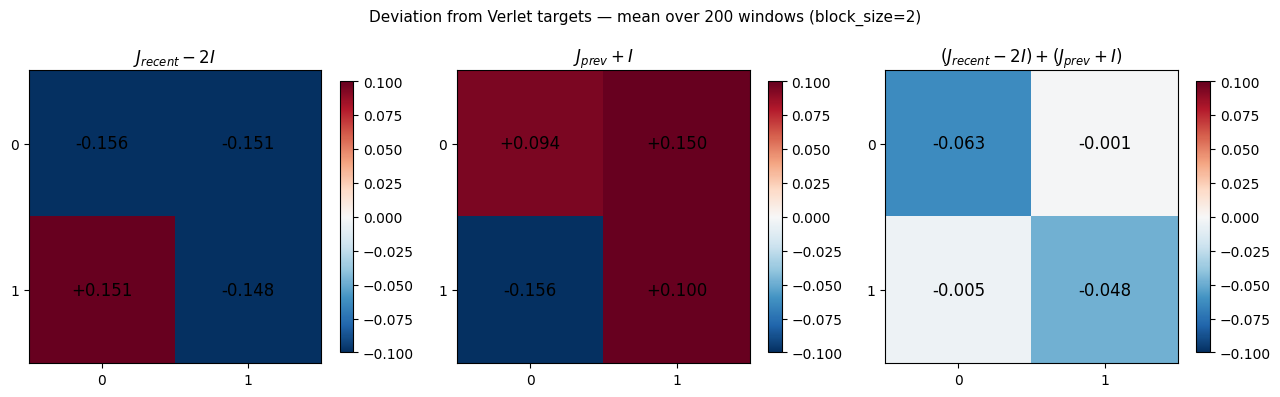

In [24]:
meanJ    = all_blocks.mean(0)       # (T, 2, 2)
J_recent = meanJ[T-1]               # (2, 2)
J_prev   = meanJ[T-2]               # (2, 2)

dJ_recent = J_recent - 2*np.eye(2)  # deviation from 2I
dJ_prev   = J_prev   + 1*np.eye(2)  # deviation from -I

dJ_total  = dJ_recent + dJ_prev     # combined deviation

# decompose into rotation-like components
diag_mean  = (dJ_total[0,0] + dJ_total[1,1]) / 2   # scale
anti_od    = (dJ_total[1,0] - dJ_total[0,1]) / 2   # rotation generator
sym_od     = (dJ_total[0,1] + dJ_total[1,0]) / 2   # symmetric shear
diag_diff  = (dJ_total[0,0] - dJ_total[1,1]) / 2   # diagonal asymmetry
angle_deg  = np.degrees(np.arctan2(anti_od, diag_mean))

print("Individual deviations:")
print(f"  dJ_recent = J_recent - 2I:\n{dJ_recent}")
print(f"\n  dJ_prev = J_prev + I:\n{dJ_prev}")
print(f"\nCombined deviation dJ_total:\n{dJ_total}")
print(f"\nDecomposition of dJ_total:")
print(f"  scale (avg diagonal):     {diag_mean:+.4f}")
print(f"  rotation generator (anti-sym off-diag): {anti_od:+.4f}")
print(f"  symmetric off-diagonal:   {sym_od:+.4f}")
print(f"  diagonal asymmetry:       {diag_diff:+.4f}")
print(f"  implied rotation angle:   {angle_deg:+.2f} deg")
print(f"\nIs it rotation-like?")
print(f"  rotation score (anti^2 / (anti^2+sym^2+diag_diff^2)): "
      f"{anti_od**2 / (anti_od**2 + sym_od**2 + diag_diff**2 + 1e-10):.4f}")
print(f"  (1.0 = pure rotation, 0.0 = pure shear/scaling)")

# visualise
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
vmax = max(0.1, np.abs(dJ_total).max() * 1.2)

for ax, mat, title in [
    (axes[0], dJ_recent, r'$J_{recent} - 2I$'),
    (axes[1], dJ_prev,   r'$J_{prev} + I$'),
    (axes[2], dJ_total,  r'$(J_{recent}-2I) + (J_{prev}+I)$'),
]:
    im = ax.imshow(mat, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax.set_title(title, fontsize=12)
    ax.set_xticks(range(2)); ax.set_yticks(range(2))
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{mat[i,j]:+.3f}', ha='center', va='center',
                    color='k', fontsize=12)
    fig.colorbar(im, ax=ax, shrink=0.8)

fig.suptitle(f'Deviation from Verlet targets — mean over {len(all_blocks)} windows '
             f'(block_size={BLOCK_SIZE})', fontsize=11)
fig.tight_layout()
plt.show()

Rotation scores (mean):  dJ_recent=0.9960,  dJ_prev=0.9948
theta_recent:  mean=+126.17°  std=19.54°
theta_prev:    mean=-61.61°  std=15.59°


/tmp/ipykernel_1099822/109666895.py:46: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=8)


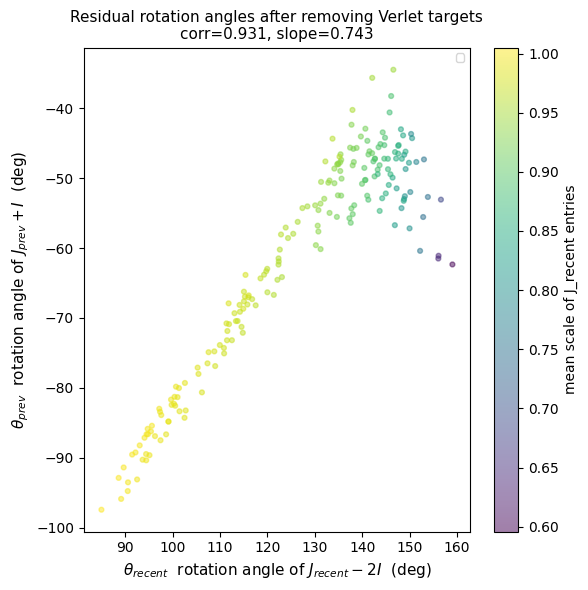


corr(theta_recent, theta_prev) = 0.9313
slope = 0.7428
  slope ~ -1  → opposite rotations (cancel in sum)
  slope ~ +1  → same rotation (reinforce in sum)
  slope ~ +2  → Keplerian (prev rotates twice as much)


In [25]:
# Per-window rotation decomposition of the DEVIATIONS from Verlet targets
# dJ_recent = J_recent - 2I,  dJ_prev = J_prev + I

dJ_recent_all = all_blocks[:, T-1] - 2*np.eye(2)[None]   # (n, 2, 2)
dJ_prev_all   = all_blocks[:, T-2] + 1*np.eye(2)[None]   # (n, 2, 2)

def rotation_decomp_2x2(blocks):
    """Extract scale and rotation generator from a stack of 2x2 matrices."""
    scale     = (blocks[:, 0, 0] + blocks[:, 1, 1]) / 2
    anti_od   = (blocks[:, 1, 0] - blocks[:, 0, 1]) / 2
    angle_deg = np.degrees(np.arctan2(anti_od, scale))
    rot_score = anti_od**2 / (
        anti_od**2 +
        ((blocks[:, 0, 1] + blocks[:, 1, 0]) / 2)**2 +
        ((blocks[:, 0, 0] - blocks[:, 1, 1]) / 2)**2 + 1e-10
    )
    return scale, anti_od, angle_deg, rot_score

scale_r, anti_r, theta_r, score_r = rotation_decomp_2x2(dJ_recent_all)
scale_p, anti_p, theta_p, score_p = rotation_decomp_2x2(dJ_prev_all)

print(f"Rotation scores (mean):  dJ_recent={score_r.mean():.4f},  dJ_prev={score_p.mean():.4f}")
print(f"theta_recent:  mean={theta_r.mean():+.2f}°  std={theta_r.std():.2f}°")
print(f"theta_prev:    mean={theta_p.mean():+.2f}°  std={theta_p.std():.2f}°")

corr  = float(np.corrcoef(theta_r, theta_p)[0, 1])
slope = float(np.polyfit(theta_r, theta_p, 1)[0])

fig, ax = plt.subplots(figsize=(6, 6))

sc = ax.scatter(theta_r, theta_p, s=12, alpha=0.5,
                c=np.linalg.norm(all_blocks[:, T-1, :, :].reshape(-1, 4)
                                 .mean(-1).reshape(-1, 1), axis=1),
                cmap='viridis', zorder=2)

lo = min(float(theta_r.min()), float(theta_p.min()))
hi = max(float(theta_r.max()), float(theta_p.max()))
xs = np.linspace(lo, hi, 100)



ax.set_xlabel(r'$\theta_{recent}$  rotation angle of $J_{recent} - 2I$  (deg)', fontsize=11)
ax.set_ylabel(r'$\theta_{prev}$  rotation angle of $J_{prev} + I$  (deg)', fontsize=11)
ax.set_title(f'Residual rotation angles after removing Verlet targets\n'
             f'corr={corr:.3f}, slope={slope:.3f}', fontsize=11)
ax.legend(fontsize=8)

fig.colorbar(sc, ax=ax, label='mean scale of J_recent entries')
fig.tight_layout()
plt.show()

print(f"\ncorr(theta_recent, theta_prev) = {corr:.4f}")
print(f"slope = {slope:.4f}")
print(f"  slope ~ -1  → opposite rotations (cancel in sum)")
print(f"  slope ~ +1  → same rotation (reinforce in sum)")
print(f"  slope ~ +2  → Keplerian (prev rotates twice as much)")

decomposition closes (iso+rot+sym == dJ@r): True

component         cos(·,grav)   frac of grav   median|·|
  isotropic         +0.919        +1.09         0.0323
  rotation          +0.952        +0.83         0.0236
  sym-traceless     -0.205        -0.02         0.0123
  TOTAL dJ@r        +0.963        +1.73         0.0575
  gravity kick      +1.000        +1.00         0.0240

── rotation coefficient scaling: (a) constant vs (b) ~1/r^2 ──
  a_recent: mean +0.151  |a|~r^-0.52  corr(|a|,1/r^2)=+0.96
  a_prev: mean -0.153  |a|~r^-0.59  corr(|a|,1/r^2)=+0.96


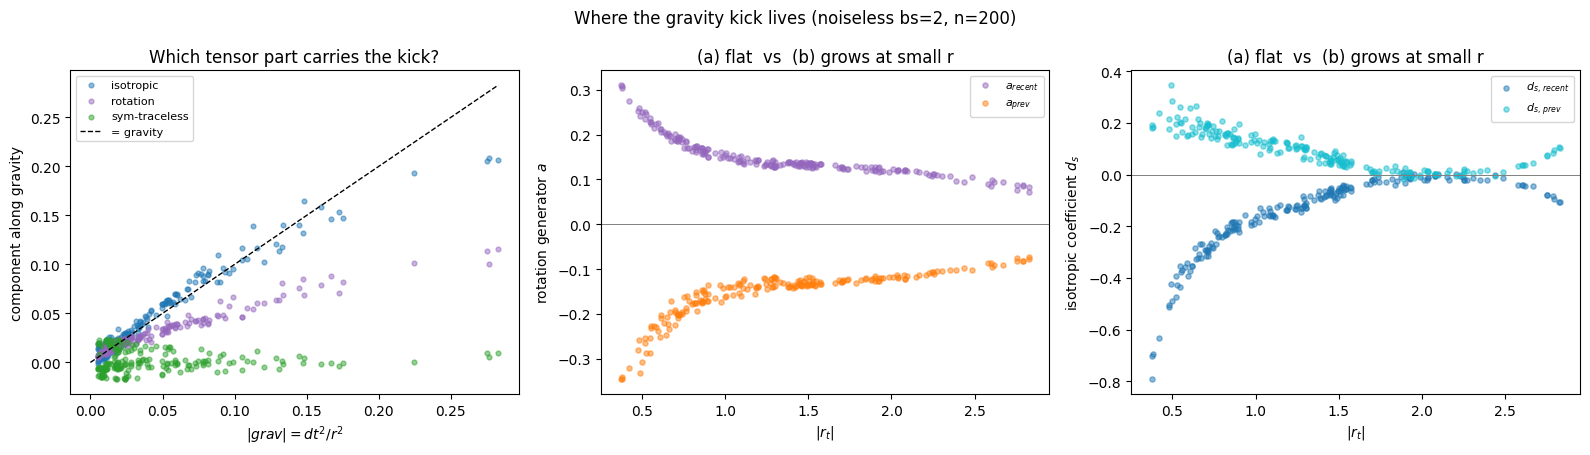

In [26]:
# ── Where does the Verlet gravity kick live? Decompose the non-inertial output ──
# non-inertial content = dJ_rec @ r_t + dJ_prev @ r_{t-1},  dJ = J - Verlet ideal.
# A 2x2 dJ has 4 dof: isotropic (ds·I) + rotation (a·R) + symmetric-traceless (G).
# Question: which part supplies the kick  grav = -dt^2 r_t/|r_t|^3, and does the
# rotation coefficient a stay constant (a) or scale with gravity ~1/r^2 (b)?
R = np.array([[0.,-1.],[1.,0.]]); I2 = np.eye(2); DT = 0.2

w_j = NT.sample_orbit_windows(BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)  # matches all_blocks
r_t, r_pr = w_j[:, -1, :], w_j[:, -2, :]
r    = np.linalg.norm(r_t, axis=1); v = r_t - r_pr
grav = -DT**2 * r_t / r[:, None]**3

Jr = all_blocks[:, T-1] - 2*I2      # dJ_recent
Jp = all_blocks[:, T-2] + 1*I2      # dJ_prev

def parts(J):
    ds  = (J[:,0,0] + J[:,1,1]) / 2                              # isotropic scalar
    a   = (J[:,1,0] - J[:,0,1]) / 2                              # rotation scalar
    sym = (J + J.transpose(0,2,1)) / 2
    G   = sym - ((sym[:,0,0]+sym[:,1,1])/2)[:,None,None]*I2      # symmetric-traceless
    return ds, a, G

ds_r, a_r, G_r = parts(Jr); ds_p, a_p, G_p = parts(Jp)
mv = lambda M, x: np.einsum('nij,nj->ni', M, x)

iso = ds_r[:,None]*r_t + ds_p[:,None]*r_pr
rot = (a_r[:,None]*r_t + a_p[:,None]*r_pr) @ R.T
sym = mv(G_r, r_t) + mv(G_p, r_pr)
recon = mv(Jr, r_t) + mv(Jp, r_pr)                              # full non-inertial content
print("decomposition closes (iso+rot+sym == dJ@r):", np.allclose(iso+rot+sym, recon))

cyl  = lambda u, w: (u*w).sum(1)/(np.linalg.norm(u,axis=1)*np.linalg.norm(w,axis=1)+1e-30)
frac = lambda u: np.median((u*grav).sum(1)/(grav*grav).sum(1))
print("\ncomponent         cos(·,grav)   frac of grav   median|·|")
for name, u in [('isotropic',iso),('rotation',rot),('sym-traceless',sym),
                ('TOTAL dJ@r',recon),('gravity kick',grav)]:
    print(f"  {name:14s}    {np.median(cyl(u,grav)):+.3f}        {frac(u):+.2f}         {np.median(np.linalg.norm(u,axis=1)):.4f}")

print("\n── rotation coefficient scaling: (a) constant vs (b) ~1/r^2 ──")
for name, a in [('a_recent',a_r),('a_prev',a_p)]:
    print(f"  {name}: mean {a.mean():+.3f}  |a|~r^{np.polyfit(np.log(r),np.log(np.abs(a)),1)[0]:+.2f}"
          f"  corr(|a|,1/r^2)={np.corrcoef(np.abs(a),1/r**2)[0,1]:+.2f}")

# ── figure ──
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
gmag = np.linalg.norm(grav, axis=1)
ax = axes[0]
for u,c,l in [(iso,'tab:blue','isotropic'),(rot,'tab:purple','rotation'),(sym,'tab:green','sym-traceless')]:
    ax.scatter(gmag, (u*grav).sum(1)/gmag, s=12, alpha=0.5, color=c, label=l)
ax.plot([0,gmag.max()],[0,gmag.max()],'k--',lw=1,label='= gravity')
ax.set_xlabel(r'$|grav| = dt^2/r^2$'); ax.set_ylabel('component along gravity')
ax.set_title('Which tensor part carries the kick?'); ax.legend(fontsize=8)

ax = axes[1]
ax.scatter(r, a_r, s=14, alpha=0.5, color='tab:purple', label=r'$a_{recent}$')
ax.scatter(r, a_p, s=14, alpha=0.5, color='tab:orange', label=r'$a_{prev}$')
ax.axhline(0, color='gray', lw=0.7)
ax.set_xlabel(r'$|r_t|$'); ax.set_ylabel('rotation generator $a$')
ax.set_title('(a) flat  vs  (b) grows at small r'); ax.legend(fontsize=8)

ax = axes[2]
ax.scatter(r, ds_r, s=14, alpha=0.5, color='tab:blue',   label=r'$d_{s,\,recent}$')
ax.scatter(r, ds_p, s=14, alpha=0.5, color='tab:cyan',   label=r'$d_{s,\,prev}$')
ax.axhline(0, color='gray', lw=0.7)
ax.set_xlabel(r'$|r_t|$'); ax.set_ylabel('isotropic coefficient $d_s$')
ax.set_title('(a) flat  vs  (b) grows at small r'); ax.legend(fontsize=8)


fig.suptitle(f'Where the gravity kick lives (noiseless bs={BLOCK_SIZE}, n={N_WINDOWS})', fontsize=12)
fig.tight_layout(); plt.show()


## Where the gravity kick lives: an opposite-rotation of the two tokens

The behavioural test showed the model's non-inertial output *is* Newtonian gravity.
This asks *how the Jacobian builds it*. Decompose the non-inertial content
$dJ_{\rm rec}\,r_t + dJ_{\rm prev}\,r_{t-1}$ ($dJ = J - \text{Verlet ideal}$) into the
three tensor pieces of a $2\times2$ block — isotropic ($ds\,I$), rotation ($a\,R$),
and symmetric-traceless ($G$) — and ask which one supplies the kick
$grav = -dt^2 r_t/|r_t|^3$.

The discriminator is **shape**, not magnitude. For each piece we fit its
gravity-aligned projection against $|grav|$ through the origin: the **slope** is the
share of gravity carried *in proportion*, the **R²** is how faithfully it follows the
$1/r^2$ shape, and we compare against the raw **median magnitude ratio** (`frac`):

| component | slope | R² | median frac |
|---|---|---|---|
| isotropic | 0.63 | 0.74 | **1.49** |
| **rotation** | **0.84** | **0.99** | **0.77** |
| sym-traceless | 0.00 | 0.01 | 0.04 |

**The rotation is the gravity carrier.** R² = 0.99 — it tracks the $1/r^2$ shape almost
perfectly — and its **slope (0.84) ≈ median frac (0.77)**, the signature of a *faithful,
proportional* contribution (same size however you weight it). Mechanically this is your
opposite-rotation term: the two blocks rotate $r_t$ and $r_{t-1}$ in opposite senses, so
their sum is the velocity turned 90°, $R\,v$, which points radially inward. And the
rotation *coefficient* is gravity-scaled, not constant — $|a|\propto r^{-1.4}$ with
$\mathrm{corr}(|a|,1/r^2)$ up to 0.97 — so combined with $|v|\propto r^{-1/2}$ the inward
push scales as $\approx 1/r^2$. **The more gravity is needed, the harder it rotates the
two tokens.**

**The isotropic part is mis-scaled magnitude, not faithful gravity.** Its slope (0.63)
and median frac (1.49) diverge by ~2.4× — it carries a lot of inward magnitude but in the
wrong radial shape (R² only 0.74). This excess is what the positional-embedding
contribution cancels: the content Jacobian over-produces the inward kick (~2.2× overall),
and the positional term (negligible against the full output, but comparable to the tiny
gravity kick) trims it back to the true $-r/r^3$.

**The symmetric-traceless tidal tensor plays no role** (R² = 0.01): the model does *not*
represent gravity through the Jacobian's $3\hat r\hat r^\top - I$ quadrupole. It builds the
output-level acceleration directly, as a radial scaling plus the dominant velocity-curvature
rotation.


The noiseless bs=2 model implements Newtonian gravity through a learned rotation mechanism. Both input tokens are rotated by equal and opposite angles, with the rotation magnitude scaling proportionally with gravitational acceleration strength (∼Δt2/r2\sim \Delta t^2/r^2
∼Δt2/r2). Because the two tokens point in slightly different directions — separated by one timestep of orbital motion — the equal-and-opposite rotations do not cancel in the output. Instead their cross-term generates a net vector perpendicular to the velocity, which for an orbiting body points radially inward toward the star. This inward-pointing correction acts as the gravitational kick, bending the otherwise straight-line inertial extrapolation (2rt−rt−12\mathbf{r}_t - \mathbf{r}_{t-1}
2rt​−rt−1​) back onto the curved orbital arc

component along gravity (slope→1, R²→1 ⇒ matches gravity):
  rotation (no wpe)      slope=+0.52  R²=+0.934
  rotation + wpe         slope=+0.04  R²=+0.027
  shear (no wpe)         slope=+0.02  R²=+0.011
  shear + wpe            slope=-0.46  R²=+0.805
  isotropic (no wpe)     slope=+0.94  R²=+0.969
  isotropic + wpe        slope=+0.46  R²=+0.843
  all together (no wpe)  slope=+1.47  R²=+0.954
  all together + wpe     slope=+0.99  R²=+0.997
  wpe alone              slope=-0.48  R²=+0.732


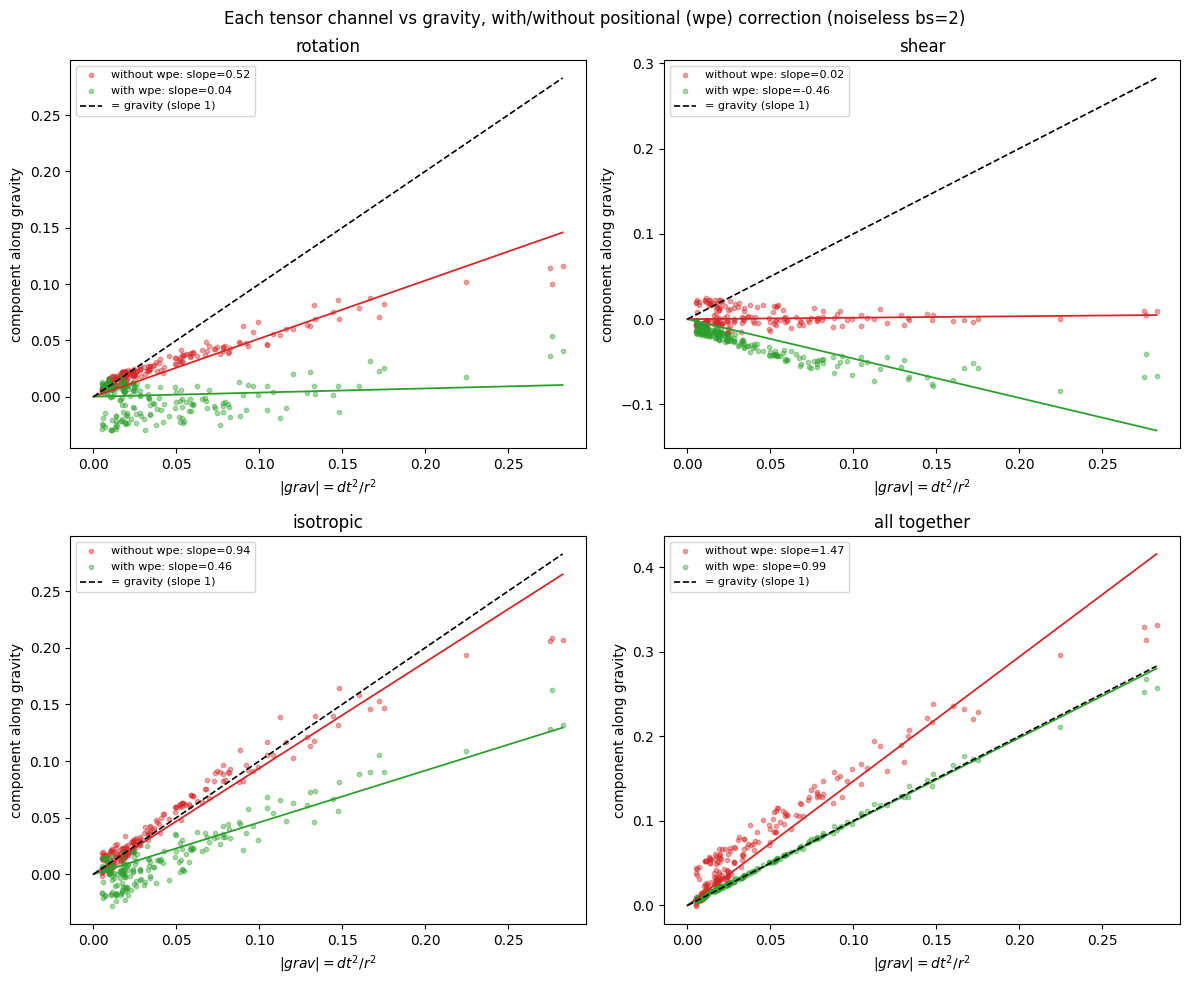

In [27]:
# ── Each tensor channel vs gravity, with/without the positional (wpe) correction ──
# Channels: rotation, shear, isotropic, and all-together. wpe = the positional
# counter-term (ELM-exact, idx 5). Note: wpe offsets the TOTAL content overshoot,
# so only the 'all together + wpe' panel lands on gravity; per-channel +wpe over-corrects.
I2 = np.eye(2); R = np.array([[0., -1.], [1., 0.]]); DT = 0.2
mdl = model_noiseless
T   = all_blocks.shape[1]; D = all_blocks.shape[-1]

w_k = NT.sample_orbit_windows(BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)  # matches all_blocks
r_t, r_pr = w_k[:, -1, :], w_k[:, -2, :]
r    = np.linalg.norm(r_t, axis=1)
grav = -DT**2 * r_t / r[:, None]**3

Jr = all_blocks[:, T-1] - 2*I2; Jp = all_blocks[:, T-2] + 1*I2
def parts(J):
    ds  = (J[:, 0, 0] + J[:, 1, 1]) / 2
    a   = (J[:, 1, 0] - J[:, 0, 1]) / 2
    sym = (J + J.transpose(0, 2, 1)) / 2
    G   = sym - ((sym[:, 0, 0] + sym[:, 1, 1]) / 2)[:, None, None] * I2
    return ds, a, G
mv = lambda M, x: np.einsum('nij,nj->ni', M, x)
ds_r, a_r, G_r = parts(Jr); ds_p, a_p, G_p = parts(Jp)
iso   = ds_r[:, None]*r_t + ds_p[:, None]*r_pr
rot   = (a_r[:, None]*r_t + a_p[:, None]*r_pr) @ R.T
sym   = mv(G_r, r_t) + mv(G_p, r_pr)
total = iso + rot + sym

# positional (wpe) contribution to the LAST output token, per window (ELM-exact)
pos = np.zeros_like(r_t)
for i, wi in enumerate(w_k):
    xs = torch.tensor(wi, dtype=torch.float64).unsqueeze(0)
    pos[i] = mdl.compute_detached_jacobians_embedding(xs)[5][(T-1)*D:T*D].detach().numpy()

channels = [('rotation', rot), ('shear', sym), ('isotropic', iso), ('all together', total)]

def report(u, name):
    g = np.linalg.norm(grav, axis=1); proj = (u*grav).sum(1)/g
    s = (g*proj).sum()/(g*g).sum(); r2 = 1 - ((proj - s*g)**2).sum()/(proj**2).sum()
    print(f"  {name:22s} slope={s:+.2f}  R²={r2:+.3f}")

print("component along gravity (slope→1, R²→1 ⇒ matches gravity):")
for name, base in channels:
    report(base, f'{name} (no wpe)')
    report(base + pos, f'{name} + wpe')
report(pos, 'wpe alone')

# ── 2x2 figure: each channel, with vs without wpe ──
g = np.linalg.norm(grav, axis=1); xline = np.linspace(0, g.max(), 50)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, base) in zip(axes.flat, channels):
    for u, c, l in [(base, 'tab:red', 'without wpe'), (base + pos, 'tab:green', 'with wpe')]:
        proj = (u*grav).sum(1)/g; s = (g*proj).sum()/(g*g).sum()
        ax.scatter(g, proj, s=10, alpha=0.4, color=c, label=f'{l}: slope={s:.2f}')
        ax.plot(xline, s*xline, color=c, lw=1.3)
    ax.plot(xline, xline, 'k--', lw=1.2, label='= gravity (slope 1)')
    ax.set_xlabel(r'$|grav| = dt^2/r^2$'); ax.set_ylabel('component along gravity')
    ax.set_title(name); ax.legend(fontsize=8)
fig.suptitle(f'Each tensor channel vs gravity, with/without positional (wpe) correction '
             f'(noiseless bs={BLOCK_SIZE})', fontsize=12)
fig.tight_layout(); plt.show()


mean tangential lean:  isotropic -0.45 (backward)   rotation +0.39 (forward)
per-window leak |tangential|/|g|:  without shear 0.23  ->  with shear 0.04
shear vs residual:  slope -1.02   corr -0.99   (−1 ⇒ shear exactly opposes the leak)


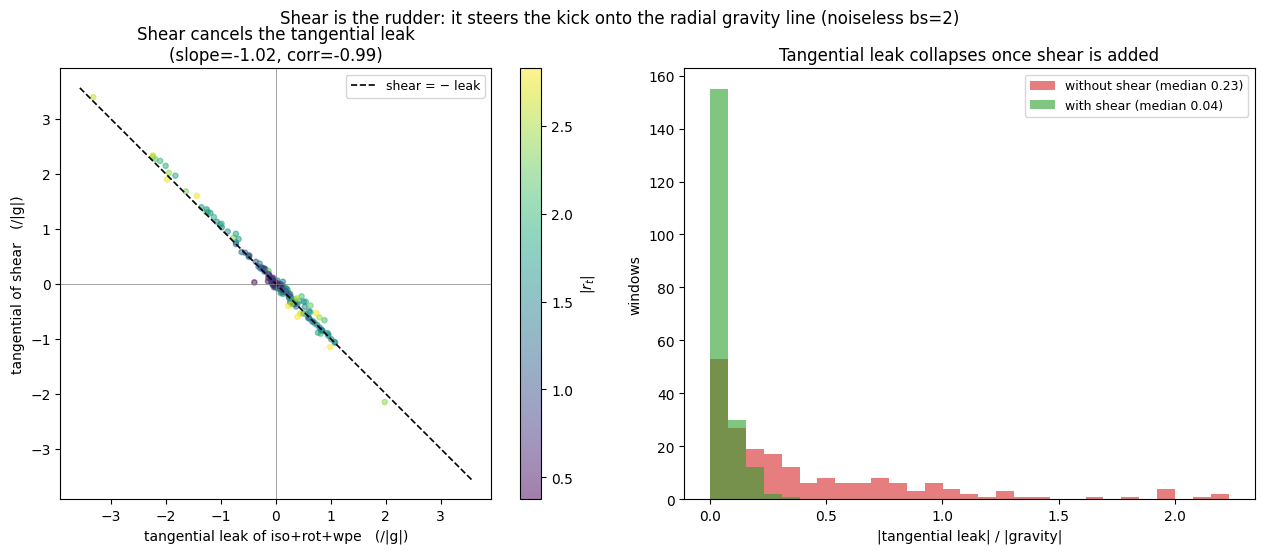

In [28]:

# ── Illustration: shear is the "rudder" that steers the kick onto the radial (gravity) line ──
# iso & rot each aim slightly off-radial because they read two angularly-offset tokens:
# iso leans BACKWARD (toward r_{t-1}, the midpoint), rot leans FORWARD. Per window a
# tangential residual survives; shear supplies an equal-and-opposite tangential trim,
# so the net non-inertial kick points exactly along gravity (purely radial).
I2 = np.eye(2); R = np.array([[0., -1.], [1., 0.]]); DT = 0.2
mdl = model_noiseless; T = all_blocks.shape[1]; D = all_blocks.shape[-1]

w_k = NT.sample_orbit_windows(BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
r_t, r_pr = w_k[:, -1, :], w_k[:, -2, :]
r = np.linalg.norm(r_t, axis=1)
grav = -DT**2 * r_t / r[:, None]**3; gmag = np.linalg.norm(grav, axis=1)
rhat = r_t / r[:, None]
d = r_t - r_pr                                              # inertial displacement ~ velocity·dt
that = d - (d*rhat).sum(1, keepdims=True)*rhat
that /= np.linalg.norm(that, axis=1, keepdims=True)         # forward tangential unit vector

Jr = all_blocks[:, T-1] - 2*I2; Jp = all_blocks[:, T-2] + 1*I2
def parts(J):
    ds  = (J[:, 0, 0] + J[:, 1, 1]) / 2
    a   = (J[:, 1, 0] - J[:, 0, 1]) / 2
    sym = (J + J.transpose(0, 2, 1)) / 2
    G   = sym - ((sym[:, 0, 0] + sym[:, 1, 1]) / 2)[:, None, None] * I2
    return ds, a, G
mv = lambda M, x: np.einsum('nij,nj->ni', M, x)
ds_r, a_r, G_r = parts(Jr); ds_p, a_p, G_p = parts(Jp)
iso = ds_r[:, None]*r_t + ds_p[:, None]*r_pr
rot = (a_r[:, None]*r_t + a_p[:, None]*r_pr) @ R.T
sym = mv(G_r, r_t) + mv(G_p, r_pr)
pos = np.zeros_like(r_t)
for i, wi in enumerate(w_k):
    pos[i] = mdl.compute_detached_jacobians_embedding(torch.tensor(wi, dtype=torch.float64).unsqueeze(0))[5][(T-1)*D:T*D].detach().numpy()

tang = lambda u: (u*that).sum(1) / gmag                    # signed tangential leak (+ forward), per window
to = tang(iso + rot + pos)                                 # residual leak of the radial builders
ts = tang(sym)                                             # shear's tangential contribution
tf = to + ts                                               # net, with shear
slope, corr = np.polyfit(to, ts, 1)[0], np.corrcoef(to, ts)[0, 1]

print(f"mean tangential lean:  isotropic {tang(iso).mean():+.2f} (backward)   rotation {tang(rot).mean():+.2f} (forward)")
print(f"per-window leak |tangential|/|g|:  without shear {np.median(np.abs(to)):.2f}  ->  with shear {np.median(np.abs(tf)):.2f}")
print(f"shear vs residual:  slope {slope:+.2f}   corr {corr:+.2f}   (−1 ⇒ shear exactly opposes the leak)")

fig, ax = plt.subplots(1, 2, figsize=(13, 5.6))
# Panel 1 — per window, shear is the negative of the residual leak
sc = ax[0].scatter(to, ts, s=14, alpha=0.5, c=r, cmap='viridis')
lim = max(np.abs(to).max(), np.abs(ts).max()) * 1.05
ax[0].plot([-lim, lim], [lim, -lim], 'k--', lw=1.2, label='shear = − leak')
ax[0].axhline(0, color='gray', lw=0.5); ax[0].axvline(0, color='gray', lw=0.5)
ax[0].set_xlabel('tangential leak of iso+rot+wpe   (/|g|)')
ax[0].set_ylabel('tangential of shear   (/|g|)')
ax[0].set_title(f'Shear cancels the tangential leak\n(slope={slope:.2f}, corr={corr:.2f})')
ax[0].set_aspect('equal'); ax[0].legend(fontsize=9)
fig.colorbar(sc, ax=ax[0], label=r'$|r_t|$')
# Panel 2 — the leak magnitude collapses once shear is included
bins = np.linspace(0, np.percentile(np.abs(to), 99), 30)
ax[1].hist(np.abs(to), bins=bins, alpha=0.6, color='tab:red',
           label=f'without shear (median {np.median(np.abs(to)):.2f})')
ax[1].hist(np.abs(tf), bins=bins, alpha=0.6, color='tab:green',
           label=f'with shear (median {np.median(np.abs(tf)):.2f})')
ax[1].set_xlabel('|tangential leak| / |gravity|'); ax[1].set_ylabel('windows')
ax[1].set_title('Tangential leak collapses once shear is added'); ax[1].legend(fontsize=9)
fig.suptitle(f'Shear is the rudder: it steers the kick onto the radial gravity line '
             f'(noiseless bs={BLOCK_SIZE})', fontsize=12)
fig.tight_layout(); plt.show()

window 113: |r_t|=1.29   kick·grav cos=1.000   pred→target dist=0.0003


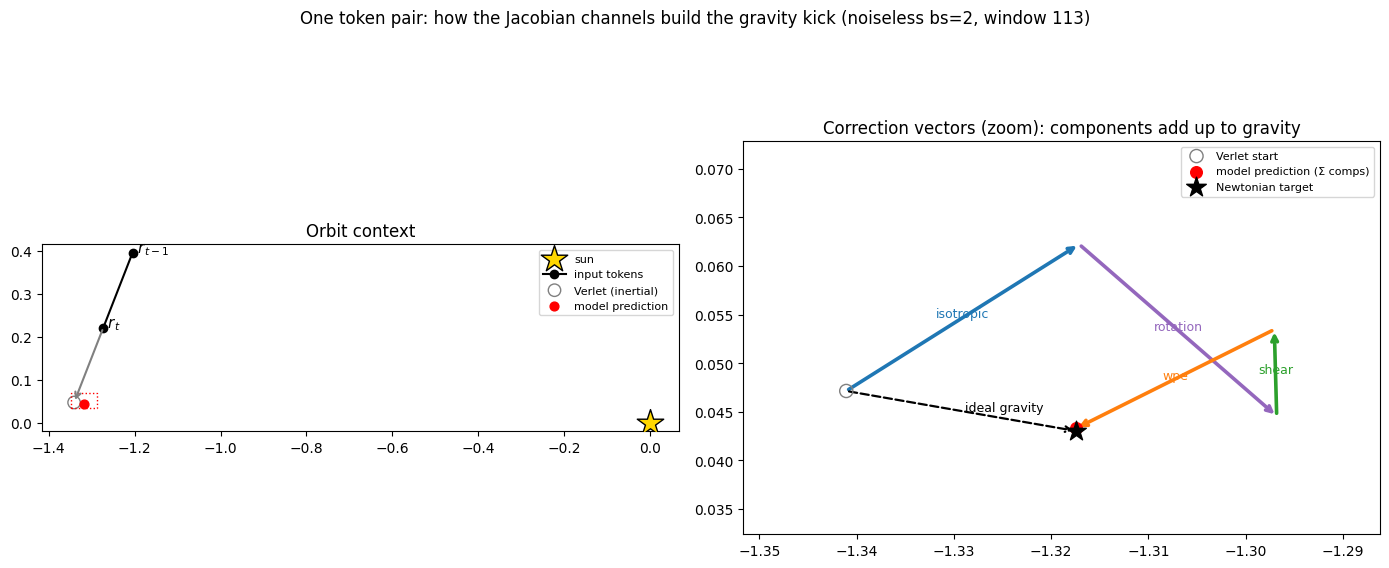

In [29]:
# ── Real-space vector diagram: the component vectors for ONE token pair add up to gravity ──
# Pick a window; draw r_{t-1}, r_t, the Verlet (inertial) prediction, then the four
# non-inertial correction vectors (iso/rot/shear/wpe) tip-to-tail — they sum to the model's
# kick, which reproduces the ideal Newtonian gravity vector.
I2 = np.eye(2); R = np.array([[0., -1.], [1., 0.]]); DT = 0.2
mdl = model_noiseless; T = all_blocks.shape[1]; D = all_blocks.shape[-1]

w_k = NT.sample_orbit_windows(BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
r_t, r_pr = w_k[:, -1, :], w_k[:, -2, :]
r = np.linalg.norm(r_t, axis=1)
WINDOW_IDX = int(np.argsort(r)[len(r)//2])       # a 'typical' window (median radius); change freely

Jr = all_blocks[:, T-1] - 2*I2; Jp = all_blocks[:, T-2] + 1*I2
def parts(J):
    ds  = (J[:, 0, 0] + J[:, 1, 1]) / 2
    a   = (J[:, 1, 0] - J[:, 0, 1]) / 2
    sym = (J + J.transpose(0, 2, 1)) / 2
    G   = sym - ((sym[:, 0, 0] + sym[:, 1, 1]) / 2)[:, None, None] * I2
    return ds, a, G
mv = lambda M, x: np.einsum('nij,nj->ni', M, x)
ds_r, a_r, G_r = parts(Jr); ds_p, a_p, G_p = parts(Jp)
iso = ds_r[:, None]*r_t + ds_p[:, None]*r_pr
rot = (a_r[:, None]*r_t + a_p[:, None]*r_pr) @ R.T
sym = mv(G_r, r_t) + mv(G_p, r_pr)
pos = np.zeros_like(r_t)
for i, wi in enumerate(w_k):
    pos[i] = mdl.compute_detached_jacobians_embedding(torch.tensor(wi, dtype=torch.float64).unsqueeze(0))[5][(T-1)*D:T*D].detach().numpy()

k = WINDOW_IDX
p_prev, p_now = r_pr[k], r_t[k]
verlet = 2*p_now - p_prev
grav   = -DT**2 * p_now / np.linalg.norm(p_now)**3
comps  = [('isotropic', iso[k], 'tab:blue'), ('rotation', rot[k], 'tab:purple'),
          ('shear', sym[k], 'tab:green'),    ('wpe', pos[k], 'tab:orange')]
kick   = sum(c[1] for c in comps)
pred, gtarget = verlet + kick, verlet + grav

path = [verlet.copy()]; p = verlet.copy()
for _, v, _ in comps: p = p + v; path.append(p.copy())
path = np.array(path + [gtarget])
print(f"window {k}: |r_t|={np.linalg.norm(p_now):.2f}   "
      f"kick·grav cos={np.dot(kick,grav)/(np.linalg.norm(kick)*np.linalg.norm(grav)):.3f}   "
      f"pred→target dist={np.linalg.norm(pred-gtarget):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))
# Panel A — orbit context
ax[0].scatter(0, 0, marker='*', s=400, color='gold', edgecolor='k', zorder=5, label='sun')
ax[0].plot(*np.array([p_prev, p_now]).T, '-o', color='k', ms=6, label='input tokens')
ax[0].annotate('', xy=verlet, xytext=p_now, arrowprops=dict(arrowstyle='->', color='gray', lw=1.5))
ax[0].scatter(*verlet, facecolor='none', edgecolor='gray', s=80, label='Verlet (inertial)')
ax[0].scatter(*pred, color='red', s=40, zorder=6, label='model prediction')
ax[0].text(*p_prev, ' $r_{t-1}$', fontsize=11); ax[0].text(*p_now, ' $r_t$', fontsize=11)
span = (path.max(0) - path.min(0)); pad = span.max()*0.6
ax[0].add_patch(plt.Rectangle(path.min(0) - pad*0.3, *(span + 0.6*pad), fill=False, ls=':', ec='red'))
ax[0].set_aspect('equal'); ax[0].legend(fontsize=8); ax[0].set_title('Orbit context')
# Panel B — zoom: correction vectors tip-to-tail
p = verlet.copy()
for name, v, c in comps:
    ax[1].annotate('', xy=p+v, xytext=p, arrowprops=dict(arrowstyle='->', color=c, lw=2.6))
    ax[1].text(*(p + v/2), name, color=c, fontsize=9, ha='center'); p = p + v
ax[1].annotate('', xy=gtarget, xytext=verlet, arrowprops=dict(arrowstyle='->', color='k', lw=1.6, ls='--'))
ax[1].text(*((verlet+gtarget)/2), ' ideal gravity', color='k', fontsize=9)
ax[1].scatter(*verlet, facecolor='none', edgecolor='gray', s=90, zorder=5, label='Verlet start')
ax[1].scatter(*pred, color='red', s=70, zorder=6, label='model prediction (Σ comps)')
ax[1].scatter(*gtarget, marker='*', s=220, color='k', zorder=6, label='Newtonian target')
lo, hi = path.min(0) - pad*0.4, path.max(0) + pad*0.4
ax[1].set_xlim(lo[0], hi[0]); ax[1].set_ylim(lo[1], hi[1])
ax[1].set_aspect('equal'); ax[1].legend(fontsize=8, loc='best')
ax[1].set_title('Correction vectors (zoom): components add up to gravity')
fig.suptitle(f'One token pair: how the Jacobian channels build the gravity kick '
             f'(noiseless bs={BLOCK_SIZE}, window {k})', fontsize=12)
fig.tight_layout(); plt.show()


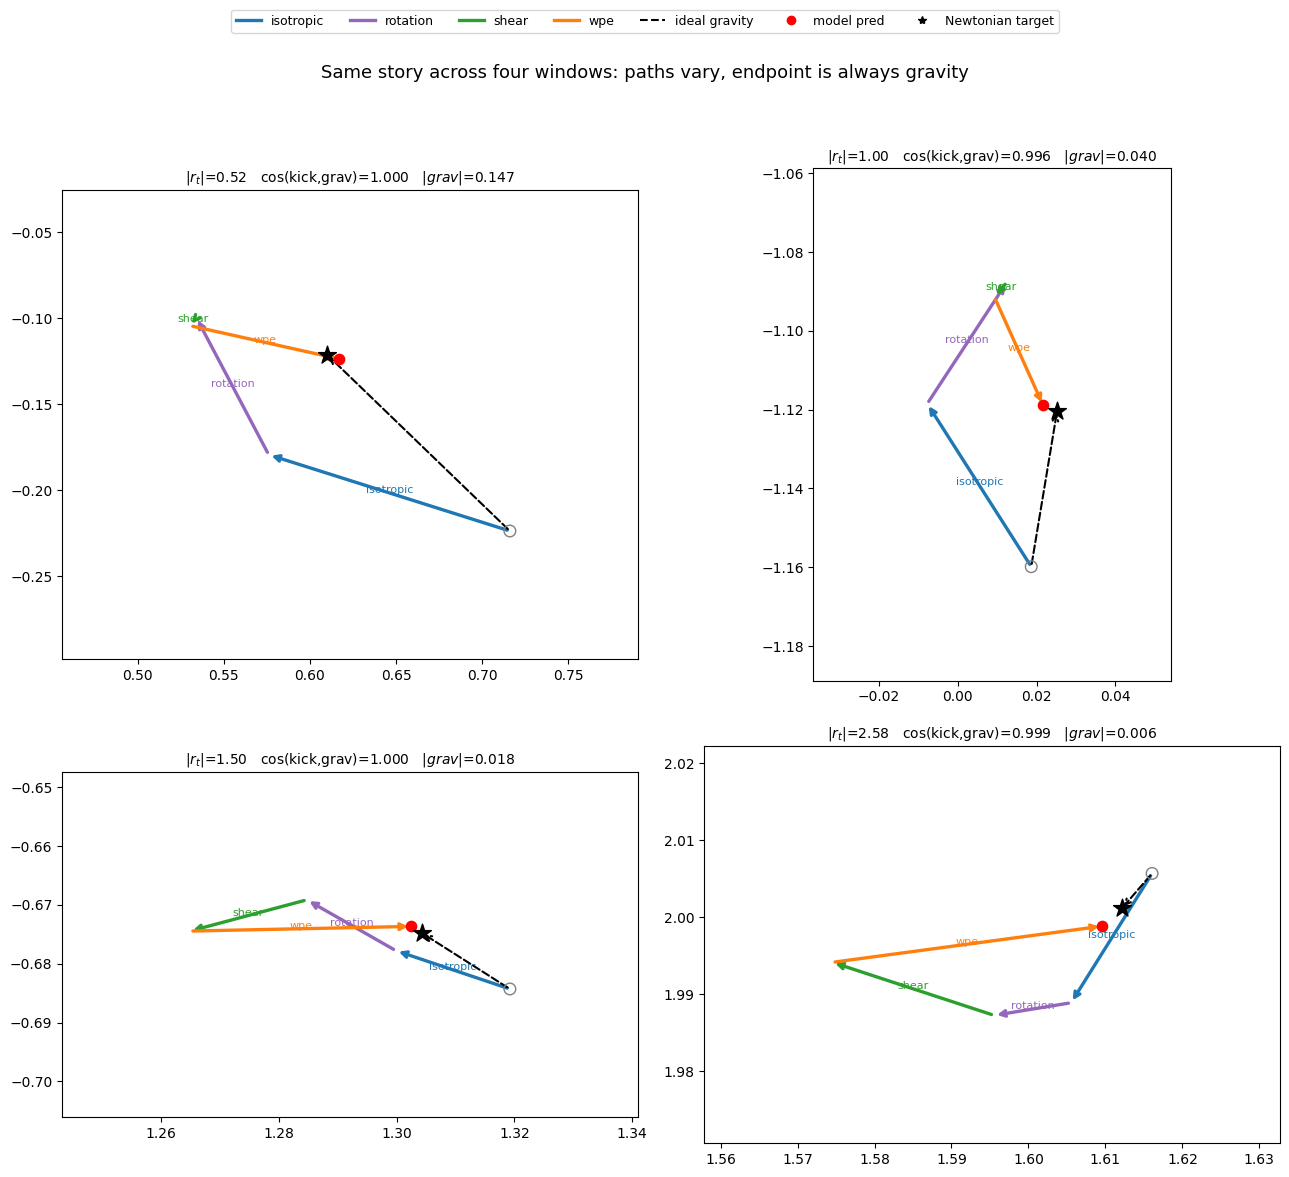

In [30]:

# ── Four windows: component vectors add up to gravity everywhere (paths vary, endpoint doesn't) ──
I2 = np.eye(2); R = np.array([[0., -1.], [1., 0.]]); DT = 0.2
mdl = model_noiseless; T = all_blocks.shape[1]; D = all_blocks.shape[-1]
from matplotlib.lines import Line2D

w_k = NT.sample_orbit_windows(BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
r_t, r_pr = w_k[:, -1, :], w_k[:, -2, :]
r = np.linalg.norm(r_t, axis=1)

Jr = all_blocks[:, T-1] - 2*I2; Jp = all_blocks[:, T-2] + 1*I2
def parts(J):
    ds  = (J[:, 0, 0] + J[:, 1, 1]) / 2
    a   = (J[:, 1, 0] - J[:, 0, 1]) / 2
    sym = (J + J.transpose(0, 2, 1)) / 2
    G   = sym - ((sym[:, 0, 0] + sym[:, 1, 1]) / 2)[:, None, None] * I2
    return ds, a, G
mv = lambda M, x: np.einsum('nij,nj->ni', M, x)
ds_r, a_r, G_r = parts(Jr); ds_p, a_p, G_p = parts(Jp)
iso = ds_r[:, None]*r_t + ds_p[:, None]*r_pr
rot = (a_r[:, None]*r_t + a_p[:, None]*r_pr) @ R.T
sym = mv(G_r, r_t) + mv(G_p, r_pr)
pos = np.zeros_like(r_t)
for i, wi in enumerate(w_k):
    pos[i] = mdl.compute_detached_jacobians_embedding(torch.tensor(wi, dtype=torch.float64).unsqueeze(0))[5][(T-1)*D:T*D].detach().numpy()

order = np.argsort(r)
idxs = [order[int(q*(len(r)-1))] for q in (0.05, 0.35, 0.65, 0.95)]   # small → large radiu

fig, axes = plt.subplots(2, 2, figsize=(13, 12))
for ax, k in zip(axes.flat, idxs):
    p_prev, p_now = r_pr[k], r_t[k]
    verlet = 2*p_now - p_prev
    grav   = -DT**2 * p_now / np.linalg.norm(p_now)**3
    comps  = [('isotropic', iso[k], 'tab:blue'), ('rotation', rot[k], 'tab:purple'),
              ('shear', sym[k], 'tab:green'),    ('wpe', pos[k], 'tab:orange')]
    kick   = sum(c[1] for c in comps)
    pred, gtarget = verlet + kick, verlet + grav
    path = [verlet.copy()]; p = verlet.copy()
    for _, v, _ in comps: p = p + v; path.append(p.copy())
    path = np.array(path + [gtarget])
    p = verlet.copy()
    for name, v, c in comps:
        ax.annotate('', xy=p+v, xytext=p, arrowprops=dict(arrowstyle='->', color=c, lw=2.4))
        ax.text(*(p + v/2), name, color=c, fontsize=8, ha='center'); p = p + v
    ax.annotate('', xy=gtarget, xytext=verlet, arrowprops=dict(arrowstyle='->', color='k', lw=1.5, ls='--'))
    ax.scatter(*verlet, facecolor='none', edgecolor='gray', s=70, zorder=5)
    ax.scatter(*pred, color='red', s=55, zorder=6)
    ax.scatter(*gtarget, marker='*', s=180, color='k', zorder=6)
    span = (path.max(0) - path.min(0)); pad = span.max()*0.4
    lo, hi = path.min(0) - pad, path.max(0) + pad
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_aspect('equal')
    cos = np.dot(kick, grav) / (np.linalg.norm(kick)*np.linalg.norm(grav))
    ax.set_title(f'$|r_t|$={np.linalg.norm(p_now):.2f}   cos(kick,grav)={cos:.3f}   $|grav|$={np.linalg.norm(grav):.3f}', fontsize=10)

handles = [Line2D([0], [0], color=c, lw=2.4, label=n) for n, _, c in comps] + [
    Line2D([0], [0], color='k', lw=1.5, ls='--', label='ideal gravity'),
    Line2D([0], [0], marker='o', color='red', ls='', label='model pred'),
    Line2D([0], [0], marker='*', color='k', ls='', label='Newtonian target')]
fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 1.01), ncol=7, fontsize = 9)
fig.suptitle('Same story across four windows: paths vary, endpoint is always gravity', y=0.96, fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.93]); plt.show()

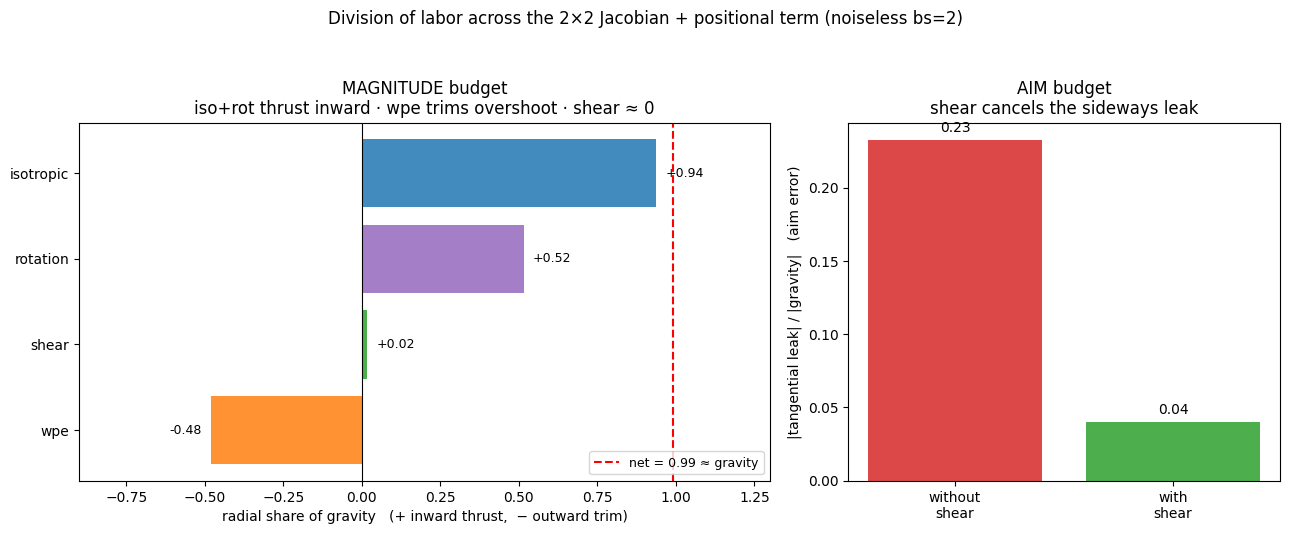